# NicheJEPA Tutorial

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 30.06.2025
- Date of Last Modification: 30.06.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import multiprocessing as mp
try:
    mp.set_start_method("spawn", force=True)
except RuntimeError:
    # start method already set in this kernel; restart the kernel if needed
    pass


In [3]:
import sys
sys.path.append("../../utils")

In [4]:
import torch

In [37]:
import logging
import os
import warnings
from tqdm import tqdm
import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                        get_gene_embed)
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from datasets import load_from_disk

from analysis_utils import *
from benchmarking_utils import max_overlap_plot
from datasets import concatenate_datasets
import pickle
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize
import torch
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity


### 1.2 Configure Paths

In [6]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/lotfollahi/sb75/nichejepa-reproducibility/artifacts'
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055'
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/18062025_082526_412'

### 1.3 Define Config

In [7]:
min_cells_per_niche = 100
latent_cluster_key = 'predicted_niche'

### 1.4 Run Notebook Setup

In [8]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [9]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [10]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [11]:
#sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [11]:
#os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/NicheJEPA', exist_ok=True)

## 2. Analysis

### 2.1 xhk1007-CV1-41b_1p (Xenium Human Kidney)

In [12]:
!ls /nfs/team361/sb75/DATASETS/bronze/xhk1014-4b_1p/xenium_annotation_adata.h5ad

/nfs/team361/sb75/DATASETS/bronze/xhk1014-4b_1p/xenium_annotation_adata.h5ad


In [13]:
dataset_name = 'xhk1007-CV1-41b_1p'
cell_type_key = 'level_1_cell_type'
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-2.h5ad'

In [124]:
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/bronze/xhk1014-4b_1p/xenium_annotation_adata.h5ad'
adata = sc.read_h5ad(file_path)

#### 2.1.1 Load Data

In [26]:
file_path= '/nfs/team361/sb75/DATASETS/bronze/xhk1014-4b_1p/xenium_annotation_adata.h5ad'
adata = sc.read_h5ad(file_path)

In [95]:
adata = adata[adata.obs['sample']=='BQ4_1']

#### 2.1.2 Harmonize Data

In [24]:
adata = harmonize_adata(adata)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle
/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:714: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  adata.var.index = adata_gene_names


Number of genes with matching ensembl IDs:           469.
Number of genes skipped:           10.
STEP 2: ADDING SPECIAL VALUES...


#### 2.1.3 Tokenize Data

In [ ]:
dataset = tokenize_adata(adata,
                         model_folder_path,
                         nproc = 4,
                         processing_mode = 'parallel')

#item = dataset[0]
#print(item)

INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/18062025_082526_412/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/mv10/nemo_v6/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


In [17]:
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'

In [18]:
save_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'

In [19]:
save_dataset_path

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/xhk1007-CV1-41b_1p/CV1-KID-0-FT-2.dataset'

In [14]:
num_shards = 32

In [21]:
dataset.save_to_disk(
    save_dataset_path,
    num_shards=num_shards)

Saving the dataset (32/32 shards): 100%|██████████| 71118/71118 [01:08<00:00, 1042.92 examples/s]


#### 2.1.3 Load Tokenize Data

In [15]:
#load_dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
load_dataset_path = '/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/LPS_BQ4_2/'
load_dataset_path = '/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/LPS_BQ6_2/'
load_dataset_path = '/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/LPS_BQ6_1/'
load_dataset_path = '/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/LPS_BQ4_1/'

dataset_LPS_BQ4_1 = load_from_disk(load_dataset_path)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

In [13]:
load_dataset_path = '/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/LPS_BQ6_1/'

dataset_LPS_BQ6_1 = load_from_disk(load_dataset_path)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

In [16]:
dataset_LPS_BQ4_1

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 140491
})

In [18]:
with open('/nfs/team361/mv10/nemo_v6/nichejepa/output_embed_LPS_BQ4_1_18062025_082526_412_1000.pkl', 'rb') as f:
    output_embed_LPS_BQ4_1 = pickle.load(f)


In [22]:
output_embed_LPS_BQ4_1['token_emb'].shape

(1000, 2816, 384)

In [29]:
adata[adata.obs['cell_id'].isin(dataset_LPS_BQ4_1.select(range(1000))['cell_id'])].obs['cell_type'].value_counts()


cell_type
PCT_S1/S2                           176
IC_typeA                            142
DCT                                 119
CNT                                 108
CCD_PC                               76
cortical_TAL_LOH                     66
PCT_VCAM1                            35
PCT_S3                               27
PCT_LCN2                             26
IC_typeB                             25
CD4_T_cell                           25
CD8_T_cell                           23
OMCD_PC                              20
medullary_TAL_LOH                    20
DTL_LOH                              20
classical_monocyte                   18
tissue_macrophage                    18
B_cell                               15
medullary_fibroblast                  6
myofibroblast                         5
cortical_fibroblast                   4
cortical_PTC                          3
mast_cell                             3
capsular_fibroblast                   3
TREM2_macrophage              

In [35]:
dataset_LPS_BQ4_1.select(range(1000))[0]['gene_tokens']

tensor([16540,  1966, 12985,  ...,     0,     0,     0])

In [75]:
np.mean(output_embed_LPS_BQ4_1['token_emb'][:,0:256],axis=1)

array([[ 1.1065215 , -0.26598284, -0.04247141, ...,  2.0551653 ,
        -1.2295636 , -0.38671225],
       [ 0.94813436, -0.40191898, -0.3772685 , ...,  2.1734762 ,
        -1.171229  ,  0.08198101],
       [ 0.6346728 , -0.55722857, -0.44292685, ...,  1.3804574 ,
        -1.2715333 ,  0.21673639],
       ...,
       [ 0.7433251 , -0.86805546,  0.8520848 , ...,  1.4481986 ,
        -2.0256476 , -0.17152245],
       [ 0.36498237, -0.8539977 ,  0.8669726 , ...,  1.3609533 ,
        -2.251706  ,  0.07643259],
       [ 0.59909683, -0.6084219 ,  0.77692914, ...,  1.7090328 ,
        -2.1210768 , -0.2696176 ]], dtype=float32)

In [79]:
np.mean(output_embed_LPS_BQ4_1['token_emb'][:,:],axis=1).shape

(1000, 384)

In [ ]:
# why padding has different value between different sample
#

In [80]:
cosine_similarity(np.mean(output_embed_LPS_BQ4_1['token_emb'][:,0:256],axis=1),np.mean(output_embed_LPS_BQ4_1['token_emb'][:,:],axis=1))

array([[0.9948536 , 0.93283665, 0.9123989 , ..., 0.77702427, 0.77038   ,
        0.8090074 ],
       [0.93015504, 0.9926005 , 0.9224216 , ..., 0.8112712 , 0.8222966 ,
        0.8346405 ],
       [0.90218997, 0.916764  , 0.98767316, ..., 0.7904619 , 0.78137743,
        0.82749605],
       ...,
       [0.7803798 , 0.8238658 , 0.80567694, ..., 0.99546707, 0.9212103 ,
        0.97477454],
       [0.7762928 , 0.8399256 , 0.8016974 , ..., 0.9235991 , 0.9916518 ,
        0.92344385],
       [0.8004171 , 0.8354009 , 0.83171654, ..., 0.9724617 , 0.91436386,
        0.99021155]], dtype=float32)

In [83]:
output_embed_LPS_BQ4_1['token_emb'][0,0:256]

array([[-1.6296313 , -0.79727536, -1.1406282 , ...,  1.7601683 ,
         0.01468849, -1.4638014 ],
       [-1.3034801 , -1.716038  , -1.0329312 , ...,  1.3557802 ,
        -0.4279558 , -2.195329  ],
       [-0.17264722, -1.1818573 , -0.7559249 , ...,  1.7260792 ,
        -1.5565258 , -2.2242982 ],
       ...,
       [ 1.3646117 , -0.09277252,  0.08774753, ...,  2.2048867 ,
        -1.2430974 , -0.14221077],
       [ 1.3646117 , -0.09277252,  0.08774753, ...,  2.2048867 ,
        -1.2430974 , -0.14221077],
       [ 1.3646117 , -0.09277252,  0.08774753, ...,  2.2048867 ,
        -1.2430974 , -0.14221077]], dtype=float32)

In [84]:
output_embed_LPS_BQ4_1['token_emb'][1,0:256]

array([[-0.727572  , -0.48993775, -0.35697836, ...,  1.0607721 ,
        -1.9158349 , -0.62063956],
       [-1.2481196 , -1.5252242 , -0.03422866, ...,  0.9550475 ,
        -1.7001355 , -1.1197789 ],
       [ 0.76231104, -1.9616548 ,  0.04242009, ...,  0.4864587 ,
        -0.5097839 , -0.5557319 ],
       ...,
       [ 1.1407192 , -0.1566711 , -0.36845917, ...,  2.3909543 ,
        -1.1682875 ,  0.44797868],
       [ 1.1407192 , -0.1566711 , -0.36845917, ...,  2.3909543 ,
        -1.1682875 ,  0.44797868],
       [ 1.1407192 , -0.1566711 , -0.36845917, ...,  2.3909543 ,
        -1.1682875 ,  0.44797868]], dtype=float32)

In [51]:
# Get your data
gene_tokens = dataset_LPS_BQ4_1.select(range(1000))[10]['gene_tokens']  # tensor([16540, 1966, 12985, ..., 0, 0, 0])
second_matrix = output_embed_LPS_BQ4_1['token_emb'][10]  # shape (2816, 384)

# Step 1: Find non-zero positions in gene_tokens
nonzero_mask = gene_tokens != 0
nonzero_indices = torch.where(nonzero_mask)[0]

print(f"Number of non-zero genes: {len(nonzero_indices)}")

# Step 2: Filter second matrix using non-zero positions
filtered_matrix = second_matrix[nonzero_indices]  # shape (num_nonzero, 384)

print(f"Filtered matrix shape: {filtered_matrix.shape}")

# Step 3: Compute pairwise cosine similarity
# Convert to numpy if it's a tensor
if torch.is_tensor(filtered_matrix):
    filtered_matrix = filtered_matrix.numpy()

cosine_sim_matrix = cosine_similarity(filtered_matrix)  # shape (num_nonzero, num_nonzero)



Number of non-zero genes: 592
Filtered matrix shape: (592, 384)


In [ ]:
dataset_LPS_BQ4_1.select(range(1000))['gene_tokens'][:,0]

In [65]:
output_embed_LPS_BQ4_1['token_emb'][0,256].shape

(384,)

In [71]:
cosine_similarity(output_embed_LPS_BQ4_1['token_emb'][12,0].reshape(1,384),output_embed_LPS_BQ4_1['token_emb'][12,256].reshape(1,384))

array([[0.5691751]], dtype=float32)

In [52]:
cosine_sim_matrix

array([[1.        , 0.6428096 , 0.71477616, ..., 0.23647492, 0.24739319,
        0.14122102],
       [0.6428096 , 1.0000002 , 0.7081578 , ..., 0.2160323 , 0.2226526 ,
        0.16280288],
       [0.71477616, 0.7081578 , 1.        , ..., 0.286148  , 0.26409897,
        0.15934396],
       ...,
       [0.23647492, 0.2160323 , 0.286148  , ..., 1.        , 0.7103088 ,
        0.68355435],
       [0.24739319, 0.2226526 , 0.26409897, ..., 0.7103088 , 1.        ,
        0.64152145],
       [0.14122102, 0.16280288, 0.15934396, ..., 0.68355435, 0.64152145,
        1.        ]], dtype=float32)

In [53]:
# Method 1: Using boolean mask to exclude diagonal
n = cosine_sim_matrix.shape[0]
mask = ~np.eye(n, dtype=bool)  # True everywhere except diagonal
row_means = np.array([cosine_sim_matrix[i][mask[i]].mean() for i in range(n)])

# Method 2: More efficient vectorized approach
diag_sum = np.diag(cosine_sim_matrix)  # Diagonal values (should be 1.0)
row_sums = cosine_sim_matrix.sum(axis=1)  # Sum of each row
row_means = (row_sums - diag_sum) / (n - 1)  # (total - diagonal) / (count - 1)

# Method 3: Using numpy masking (cleaner)
np.fill_diagonal(cosine_sim_matrix, np.nan)  # Replace diagonal with NaN
row_means = np.nanmean(cosine_sim_matrix, axis=1)  # Mean ignoring NaN

print(f"Row means shape: {row_means.shape}")
print(f"Row means: {row_means}")


Row means shape: (592,)
Row means: [0.30333218 0.3438501  0.37432143 0.31473872 0.34826174 0.42640847
 0.3864248  0.31097484 0.4113288  0.31446242 0.4512735  0.3989143
 0.3946139  0.4135372  0.43850228 0.39367133 0.36977416 0.41687548
 0.36996678 0.31356168 0.41906014 0.4251976  0.39660907 0.4254194
 0.43351305 0.42517585 0.44151315 0.42722166 0.37332863 0.4066464
 0.39279166 0.44818223 0.37855422 0.40927237 0.45982844 0.44049144
 0.24624757 0.33399084 0.32894358 0.3173482  0.3484366  0.35516235
 0.34979022 0.33712476 0.27157563 0.36096248 0.39176074 0.45582324
 0.41116473 0.43091345 0.4112293  0.43880698 0.37032127 0.4401959
 0.42494777 0.45362124 0.37134644 0.37356937 0.48888087 0.44178036
 0.45969382 0.45062834 0.44055322 0.43285513 0.4639056  0.43955594
 0.44635814 0.41825163 0.3656932  0.40899667 0.45865905 0.4760337
 0.44871935 0.43774223 0.4374842  0.45433265 0.45189118 0.42359892
 0.41548023 0.45394966 0.4254776  0.43808421 0.41843855 0.40908387
 0.44877374 0.43360227 0.4262136

In [235]:
# Path to the pickle file
path = "/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/18062025_082526_412/token_dictionary.pkl"
# Load the dictionary
with open(path, "rb") as f:
    token_dict = pickle.load(f)


In [236]:
!ls /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models

03072025_001818_175  18062025_082526_412
11062025_183320_055  29062025_202056_303


In [237]:
#show that this one doesn't works
token_dict['ENSG00000248323']
#LUCAT1 

KeyError: 'ENSG00000248323'

In [239]:
from pyensembl import EnsemblRelease
ensembl = EnsemblRelease(release=110, species='human')
ensembl.download()
ensembl.index()


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


In [240]:
all_genes = ensembl.genes()
protein_coding_genes = [
        gene for gene in all_genes if gene.biotype == "protein_coding"]
mirna_genes = [
        gene for gene in all_genes if gene.biotype == "miRNA"]
all_relevant_genes = protein_coding_genes + mirna_genes
gene_ensembl_map_dict = {
        gene.gene_name: gene.gene_id for gene in all_genes}


In [250]:
gene_ensembl_map_dict_all = {
        gene.gene_name: gene.biotype for gene in all_genes}


In [251]:
gene_ensembl_map_dict_all['LUCAT1']

'lncRNA'

In [19]:
cell_ids = []
neb_ids = ['ENSG00000111537']

In [30]:
cell_tokens = np.array(list(token_dict[e] for e in cell_ids if e in token_dict))
neb_tokens  = np.array(list(token_dict[e] for e in neb_ids  if e in token_dict))
CELL_LEN = 256

In [27]:
adata.var[adata.var['ensembl_id']=='ENSG00000111537']

,ensembl_id
gene_name,
IFNG,ENSG00000111537


#### 2.1.3 Cell Filtering

In [31]:
def keep_cell_types_with_specific_gene_name(batch):
    toks = np.asarray(batch["gene_tokens"])  # shape (B, TOTAL_LEN)
    cell_hit = np.isin(toks[:, :CELL_LEN],    cell_tokens).any(axis=1)
    neb_hit  = np.isin(toks[:, CELL_LEN:],    neb_tokens).any(axis=1)
    return (cell_hit | neb_hit).tolist()  # use & for "both must match"

In [32]:
filtered_ds__LPS_BQ6_1 = dataset_LPS_BQ6_1.filter(keep_cell_types_with_specific_gene_name, batched=True, batch_size=4096,
                                                  num_proc=1)

Filter:   0%|          | 0/209771 [00:00<?, ? examples/s]

In [34]:
filtered_ds__LPS_BQ4_1 = dataset_LPS_BQ4_1.filter(keep_cell_types_with_specific_gene_name, batched=True, batch_size=4096,
                                                  num_proc=1)

Filter:   0%|          | 0/140491 [00:00<?, ? examples/s]

In [35]:
print((len(set(filtered_ds__LPS_BQ6_1['cell_id'])),len(filtered_ds__LPS_BQ6_1['cell_id'])))

(6750, 6750)


In [36]:
print((len(set(filtered_ds__LPS_BQ4_1['cell_id'])),len(filtered_ds__LPS_BQ4_1['cell_id'])))

(9960, 9960)


In [37]:
print((len(set(filtered_ds__LPS_BQ4_1['cell_id']+filtered_ds__LPS_BQ6_1['cell_id'])),
       len(filtered_ds__LPS_BQ4_1['cell_id']+filtered_ds__LPS_BQ6_1['cell_id'])))

(16710, 16710)


In [38]:
filtered_ds = concatenate_datasets([filtered_ds__LPS_BQ4_1, filtered_ds__LPS_BQ6_1])

In [39]:
print((len(set(filtered_ds['cell_id'])),
       len(filtered_ds['cell_id'])))

(16710, 16710)


In [43]:
cell_ids = filtered_ds['cell_id']

In [44]:
len(cell_ids)

16710

In [45]:
# Define perturbations
n_cells = len(cell_ids)
perturb_df = pd.DataFrame({
    'perturbed_cell_id': cell_ids,
    'perturbed_ensembl_id': ['ENSG00000111537'] * n_cells ,
    'perturbation_target': ['neighborhood'] * n_cells,
    'perturbation_type': ['knockout'] * n_cells,
    'foldchange': [np.nan] * n_cells
})


In [46]:
filtered_ds_perturb = perturb_dataset(
    dataset=filtered_ds,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path,
    batch_size=1000,
    nproc=1)

Map:   0%|          | 0/16710 [00:00<?, ? examples/s]

In [47]:
filtered_ds_perturb

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 16710
})

In [72]:
item = filtered_ds_perturb[333]

In [74]:
item1 = filtered_ds[333]

In [50]:
gene_tokens =filtered_ds["gene_tokens"]   # shape ➜ (N, 2816)
gene_expr =filtered_ds["gene_expr"]   # shape ➜ (N, 2816)

In [51]:
gene_tokens_1 =filtered_ds_perturb["gene_tokens"]   # shape ➜ (N, 2816)
gene_expr_1 =filtered_ds_perturb["gene_expr"]   # shape ➜ (N, 2816)

In [55]:
torch.sum(gene_tokens-gene_tokens_1)

tensor(0)

In [56]:
token_name = 7354

In [63]:
mask = np.where((gene_tokens_1[:,256:] == 3974).any(axis=1) & (gene_tokens_1[:,256:] == 3974).any(axis=1))
#mask = np.where((expr1[:,256:] == 7354).any(axis=1))
#mask = np.where((expr1[:,256:] == token_name).any(axis=1))

In [71]:
count = 0 
for r in mask[0].tolist():
    if (gene_tokens_1[r][256:] == 3974).any():       # or torch.isin(X[r], token_ids).any()
         # do something
        count +=1
count

16710

In [75]:
(item['gene_tokens']==3974).nonzero(as_tuple=False)

tensor([[2076]])

In [77]:
(item1['gene_tokens']==3974).nonzero(as_tuple=False)

tensor([[2076]])

In [78]:
item['gene_expr'][2076]

tensor(0.)

In [87]:
item1['gene_expr'][2076]

tensor(0.6931)

In [80]:
item['gene_tokens'][2076]

tensor(3974)

In [81]:
item1['gene_tokens'][2076]

tensor(3974)

In [69]:
token_dict['ENSG00000136869']

7354

In [68]:
token_dict['ENSG00000111537']

3974

In [93]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12

In [ ]:
# IFNG Genes
# CXCL2 'ENSG00000081041', 
#CXCL8 'ENSG00000169429' ,
#CXCL10 'ENSG00000169245',
#CXCL11 'ENSG00000169248', and 
#CCL5 'ENSG00000271503'  in GECs IFNG


#Housekeeping Gene 


# CRHBP 'ENSG00000145708', EMCN 'ENSG00000164035', MEIS2 'ENSG00000134138',
# SLC4A1 'ENSG00000004939', FOXI1 'ENSG00000168269', and DMRT2 'ENSG00000173253' 

In [97]:
adata[adata.obs['cell_type']=='GEC']

View of AnnData object with n_obs × n_vars = 12199 × 479
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'donor', 'condition', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'qc_cuts', '_scvi_batch', '_scvi_labels', 'leiden', 'celltype_clusters', 'leiden_R', 'cell_type', 'broad_cell_type', 'compartment'
    var: 'Symbol', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uui

In [98]:
cell_gene_ensembl_id = ['ENSG00000081041','ENSG00000169429',
                               'ENSG00000169245', 'ENSG00000169248',
                                'ENSG00000271503','ENSG00000145708',
                       'ENSG00000164035','ENSG00000134138',
                       'ENSG00000004939', 'ENSG00000168269','ENSG00000173253']
neighborhood_gene_ensembl_id = [
                               ] # ['all'] * len(perturbed_cell_id)

In [99]:
output_gene_embed_unperturb = get_gene_embed( dataset=filtered_ds,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.4.34.dev20240922 is installed, but it is not compatible with the installed jaxlib version 0.6.1, so it will not be used.
  warnings.warn(
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.4.34.dev20240922 is installed, but it is not compatible with the installed jaxlib version 0.6.1, so it will not be used.
  warnings.warn(
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.4.34.dev20240922 is installed, but it is not compatible with the installed jaxlib version 0.6.1, so it will not be used.
  warnings.warn(
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_

In [100]:
output_gene_embed_perturb = get_gene_embed( dataset=filtered_ds_perturb,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.4.34.dev20240922 is installed, but it is not compatible with the installed jaxlib version 0.6.1, so it will not be used.
  warnings.warn(
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.4.34.dev20240922 is installed, but it is not compatible with the installed jaxlib version 0.6.1, so it will not be used.
  warnings.warn(
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.4.34.dev20240922 is installed, but it is not compatible with the installed jaxlib version 0.6.1, so it will not be used.
  warnings.warn(
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_

In [227]:
adata

AnnData object with n_obs × n_vars = 713363 × 479
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'donor', 'condition', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'qc_cuts', '_scvi_batch', '_scvi_labels', 'leiden', 'celltype_clusters', 'leiden_R', 'cell_type', 'broad_cell_type', 'compartment'
    var: 'Symbol', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'br

In [162]:
# 1. Get the ordered list of target cell IDs
cell_ids = filtered_ds["cell_id"]

# 2. Find their positions in adata.obs["cell_id"]
obs_ids = list(adata.obs["cell_id"])
positions = [obs_ids.index(cid) for cid in cell_ids]

# 3. Subset & reorder AnnData
adata_subset = adata[positions].copy()

In [ ]:
cell_ids[0:10]

In [109]:
list(adata_subset.obs['cell_id'])==cell_ids

True

In [141]:
np.count_nonzero(np.any(adata_subset.obsm['perturbed_spatial_cell_emb_geneENSG00000168269'] != 0, axis=1))

531

In [ ]:
adata_subset.obsm['perturbed_spatial_cell_emb_geneENSG00000081041']

In [140]:
np.count_nonzero(np.any(adata_subset.obsm['unperturbed_spatial_cell_emb_geneENSG00000168269'] != 0, axis=1))

531

In [ ]:
# IFNG Genes
# CXCL2 'ENSG00000081041', 
#CXCL8 'ENSG00000169429' ,
#CXCL10 'ENSG00000169245',
#CXCL11 'ENSG00000169248', and 
#CCL5 'ENSG00000271503'  in GECs IFNG


#Housekeeping Gene 


# CRHBP 'ENSG00000145708', EMCN 'ENSG00000164035', MEIS2 'ENSG00000134138',
# SLC4A1 'ENSG00000004939', FOXI1 'ENSG00000168269', and DMRT2 'ENSG00000173253' 

In [206]:
# 4. Inject embeddings into .obsm with L2 normalization
for tag, emb_dict in [("unperturbed", output_gene_embed_unperturb),
                      ("perturbed",   output_gene_embed_perturb)]:
    for gene_key, matrix in emb_dict.items():
        # L2 normalize each row (handles zero vectors automatically)
        normalized_matrix = normalize(matrix, norm='l2', axis=1)
        adata_subset.obsm[f"{tag}_{gene_key}"] = normalized_matrix


In [222]:
# gene sets
housekeeping = {
    "ENSG00000145708", "ENSG00000164035", "ENSG00000134138",
    "ENSG00000004939", "ENSG00000168269", "ENSG00000173253"
}
ifng = {
    "ENSG00000081041", "ENSG00000169429", "ENSG00000169245",
    "ENSG00000169248", "ENSG00000271503"
}
all_genes = list(housekeeping | ifng)

CELLTYPE_COL = "broad_cell_type"  # <- change if your column name differs
cell_types = adata_subset.obs[CELLTYPE_COL].unique().tolist()

rows = []
for gid in all_genes:
    u = adata_subset.obsm[f"unperturbed_spatial_cell_emb_gene{gid}"]  # (N,D)
    v = adata_subset.obsm[f"perturbed_spatial_cell_emb_gene{gid}"]    # (N,D)

    for ct in cell_types:
        idx = (adata_subset.obs[CELLTYPE_COL].values == ct)
        if not np.any(idx):
            rows.append({
                "ensembl_id": gid,
                "emb_type": "spatial_cell_emb",
                "cell_type": ct,
                "avg_cosine": np.nan,
                "nonzero_count": 0,
                "is_housekeeping": gid in housekeeping,
            })
            continue

        u_ct = u[idx]
        v_ct = v[idx]

        dot = np.einsum("ij,ij->i", u_ct, v_ct)
        nu = np.linalg.norm(u_ct, axis=1)
        nv = np.linalg.norm(v_ct, axis=1)
        mask = (nu > 0) & (nv > 0)

        if mask.any():
            cosines = dot[mask] / (nu[mask] * nv[mask])
            avg = cosines.mean()
            cnt = int(mask.sum())
        else:
            avg, cnt = np.nan, 0

        rows.append({
            "ensembl_id": gid,
            "emb_type": "spatial_cell_emb",
            "cell_type": ct,
            "avg_cosine": avg,
            "nonzero_count": cnt,
            "is_housekeeping": gid in housekeeping,
        })

df = pd.DataFrame(rows)


In [223]:
df = df[df['nonzero_count']>20]

In [224]:
df.sort_values(by='avg_cosine').head(50)

,ensembl_id,emb_type,cell_type,avg_cosine,nonzero_count,is_housekeeping
103,ENSG00000271503,spatial_cell_emb,vasa_recta,0.999926,62,False
131,ENSG00000169248,spatial_cell_emb,immune_cell,0.999941,99,False
166,ENSG00000164035,spatial_cell_emb,vasa_recta,0.999947,124,True
40,ENSG00000169245,spatial_cell_emb,vasa_recta,0.999953,62,False
187,ENSG00000134138,spatial_cell_emb,vasa_recta,0.999956,162,True
215,ENSG00000145708,spatial_cell_emb,immune_cell,0.999966,50,True
124,ENSG00000081041,spatial_cell_emb,vasa_recta,0.999967,334,False
89,ENSG00000271503,spatial_cell_emb,immune_cell,0.999967,441,False
110,ENSG00000081041,spatial_cell_emb,immune_cell,0.999969,939,False
168,ENSG00000134138,spatial_cell_emb,PCT,0.999970,27,True


In [210]:
import numpy as np
import pandas as pd

# inputs: adata_subset with obs["cell_type"] and .obsm embeddings

house_ids = [
    "ENSG00000145708","ENSG00000164035","ENSG00000134138",
    "ENSG00000004939","ENSG00000168269","ENSG00000173253"
]
ifng_ids = [
    "ENSG00000081041","ENSG00000169429","ENSG00000169245",
    "ENSG00000169248","ENSG00000271503"
]
GROUPS = {"housekeeping": house_ids, "ifng": ifng_ids}
EMB = "spatial_cell_emb"
CT_COL = "cell_type"

def mean_emb(gene_ids, prefix, idx):
    mats = [adata_subset.obsm[f"{prefix}_{EMB}_gene{gid}"][idx] for gid in gene_ids]  # (G,n,D)
    A = np.stack(mats, 0)
    nz = (np.linalg.norm(A, axis=2) > 0)        # (G,n)
    sums = A.sum(axis=0)                        # (n,D)
    cnt = nz.sum(axis=0)[:, None]               # (n,1)
    cnt[cnt == 0] = 1                           # avoid /0; leaves zeros
    return sums / cnt                           # (n,D)

def cosine_avg_nonzero(U, V):
    nu = np.linalg.norm(U, axis=1)
    nv = np.linalg.norm(V, axis=1)
    mask = (nu > 0) & (nv > 0)
    if not mask.any():
        return np.nan, 0
    cos = np.einsum("ij,ij->i", U[mask], V[mask]) / (nu[mask] * nv[mask])
    return float(cos.mean()), int(mask.sum())

rows = []
for ct in adata_subset.obs[CT_COL].unique():
    idx = (adata_subset.obs[CT_COL].values == ct)
    for group_name, gene_ids in GROUPS.items():
        U = mean_emb(gene_ids, "unperturbed", idx)
        V = mean_emb(gene_ids, "perturbed",   idx)
        avg, n = cosine_avg_nonzero(U, V)
        rows.append({
            "cell_type": ct,
            "emb_type": EMB,
            "gene_set": group_name,            # "housekeeping" or "ifng"
            "avg_cosine": avg,
            "nonzero_count": n
        })

df_avg = pd.DataFrame(rows)


In [213]:
df_avg = df_avg[df_avg['nonzero_count']>100]

In [ ]:
#IL1B MAGIC GENE FROM MO
#PERTURB THIS IN CELL AND RANK GENE in nonclassical_monocyte/macrophage AND classical_monocyte 


In [214]:
df_avg.sort_values(by='avg_cosine').head(50)

,cell_type,emb_type,gene_set,avg_cosine,nonzero_count
78,vasa_recta,spatial_cell_emb,housekeeping,0.999960,228
53,nonclassical_monocyte/macrophage,spatial_cell_emb,ifng,0.999972,168
6,cortical_fibroblast,spatial_cell_emb,housekeeping,0.999973,219
79,vasa_recta,spatial_cell_emb,ifng,0.999974,351
11,tissue_macrophage,spatial_cell_emb,ifng,0.999975,356
23,CD4_T_cell,spatial_cell_emb,ifng,0.999978,167
69,VSMC,spatial_cell_emb,ifng,0.999978,173
15,classical_monocyte,spatial_cell_emb,ifng,0.999978,478
72,GEC,spatial_cell_emb,housekeeping,0.999979,138
60,pericyte,spatial_cell_emb,housekeeping,0.999982,183


In [ ]:
import numpy as np
import pandas as pd

# --- gene sets ---
housekeeping = {
    "ENSG00000145708","ENSG00000164035","ENSG00000134138",
    "ENSG00000004939","ENSG00000168269","ENSG00000173253"
}
ifng = {
    "ENSG00000081041","ENSG00000169429","ENSG00000169245",
    "ENSG00000169248","ENSG00000271503"
}
all_genes = list(housekeeping | ifng)

EMB = "spatial_cell_emb"
CELLTYPE_COL = "broad_cell_type"  # change if different
cell_types = adata_subset.obs[CELLTYPE_COL].unique().tolist()

_EPS = 1e-12

def mean_nonzero_rows(M):
    """
    Compute the mean vector across rows of M,
    using only rows where the vector is nonzero.
    Returns a zero vector if no nonzero rows exist.
    """
    norms = np.linalg.norm(M, axis=1)
    mask = norms > _EPS
    if not mask.any():
        return np.zeros(M.shape[1], dtype=float)
    return M[mask].mean(axis=0)

def cosine_similarity(u, v):
    """Cosine similarity between two vectors, returns NaN if either is zero."""
    nu = np.linalg.norm(u)
    nv = np.linalg.norm(v)
    if nu <= _EPS or nv <= _EPS:
        return np.nan
    return float(np.dot(u, v) / (nu * nv))

rows = []
for gid in all_genes:
    # full embedding arrays for this gene under each condition
    u = np.asarray(adata_subset.obsm[f"unperturbed_{EMB}_gene{gid}"], dtype=float)  # (N, D)
    v = np.asarray(adata_subset.obsm[f"perturbed_{EMB}_gene{gid}"], dtype=float)    # (N, D)

    for ct in cell_types:
        idx = (adata_subset.obs[CELLTYPE_COL].values == ct)
        if not np.any(idx):
            rows.append({
                "ensembl_id": gid,
                "emb_type": EMB,
                "cell_type": ct,
                "cosine": np.nan,
                "is_housekeeping": gid in housekeeping,
                "cell_count": 0
            })
            continue

        # average only over nonzero embeddings in this cell type
        u_mean = mean_nonzero_rows(u[idx])
        v_mean = mean_nonzero_rows(v[idx])
        cos = cosine_similarity(u_mean, v_mean)

        rows.append({
            "ensembl_id": gid,
            "emb_type": EMB,
            "cell_type": ct,
            "cosine": cos,
            "is_housekeeping": gid in housekeeping,
            "cell_count": int(np.sum(idx))
        })

df_ = pd.DataFrame(rows)


In [ ]:
#per cell_type rank this 
#report the gene names

In [221]:
df_.sort_values(by='cosine').head(50)

,ensembl_id,emb_type,cell_type,cosine,is_housekeeping,cell_count
81,ENSG00000168269,spatial_cell_emb,podocyte,0.999982,True,157
199,ENSG00000004939,spatial_cell_emb,medullary_TAL_LOH,0.999982,True,1396
176,ENSG00000134138,spatial_cell_emb,IC_typeB,0.999985,True,158
42,ENSG00000173253,spatial_cell_emb,PCT,0.999986,True,3123
34,ENSG00000169245,spatial_cell_emb,ATL_LOH,0.999991,False,28
51,ENSG00000173253,spatial_cell_emb,DTL_LOH,0.999992,True,492
211,ENSG00000145708,spatial_cell_emb,IC_typeA,0.999992,True,370
181,ENSG00000134138,spatial_cell_emb,ATL_LOH,0.999993,True,28
201,ENSG00000004939,spatial_cell_emb,myofibroblast,0.999993,True,392
148,ENSG00000164035,spatial_cell_emb,IC_typeA,0.999993,True,370


#### 2.1.4 Embed Data

In [888]:
emb_layer = None
top_k = None
batch_size = 192
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
cell_gene_ids = []
neighborhood_gene_ids = []

In [889]:
output_embed = embed_dataset(
    dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    include_spatial_cell_emb=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCountEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1007: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  udata[key] = udata[key].to(device, non_blocking=True)
/usr/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
732it [24:31,  2.01s/it]


In [893]:
adata.obsm['cell_emb0'] = output_embed['cell_emb']
adata.obsm['spatial_cell_emb0'] = output_embed['spatial_cell_emb']
adata.obsm['neighborhood_emb0'] = output_embed['neighborhood_emb']

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


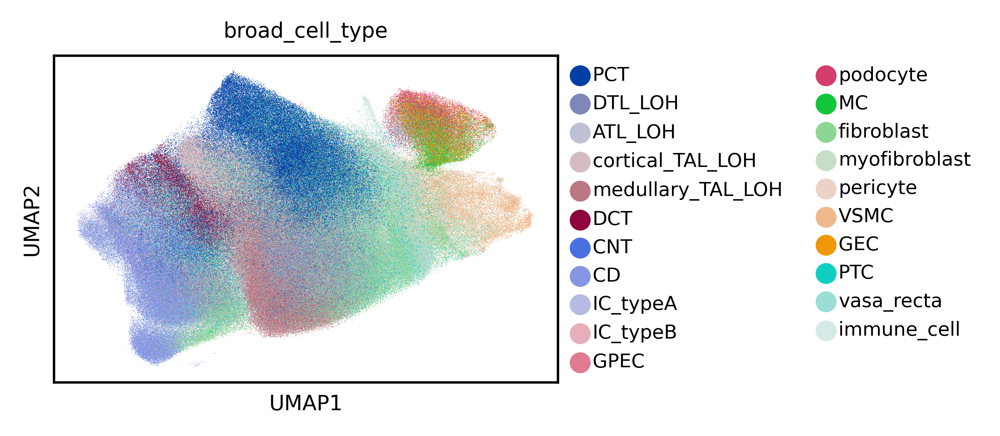

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


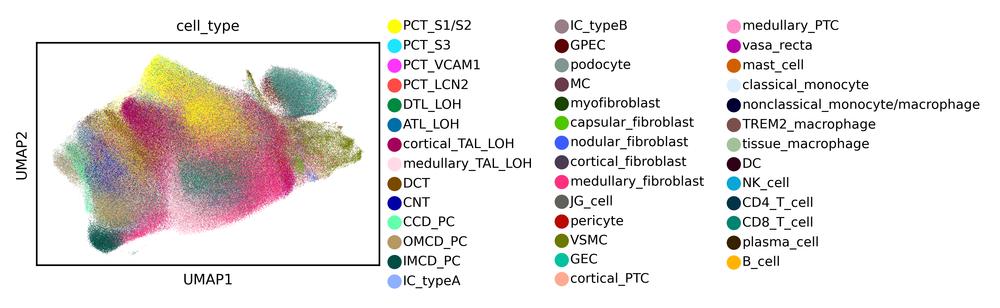

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


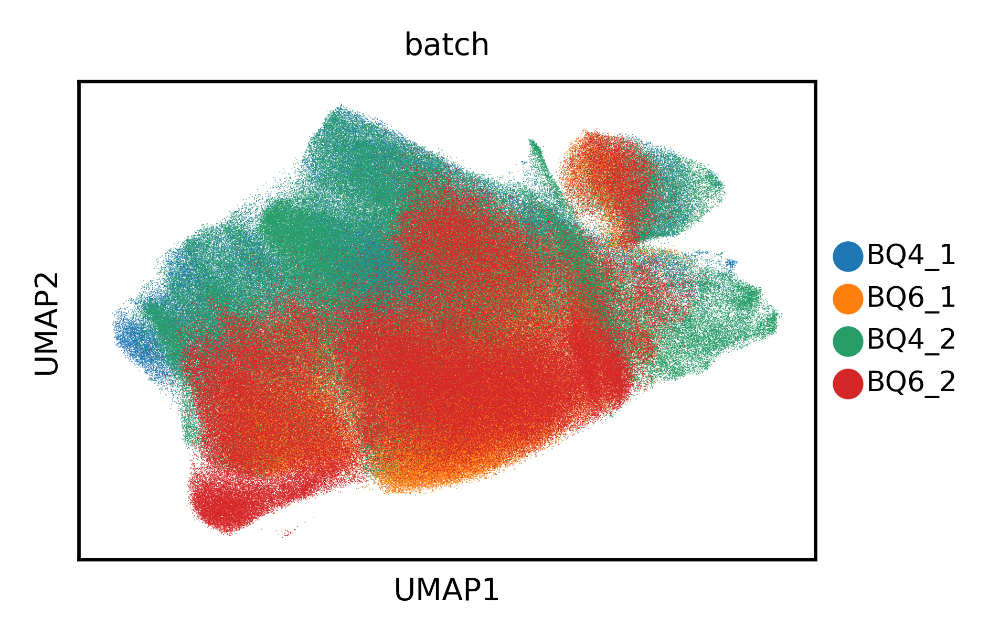

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


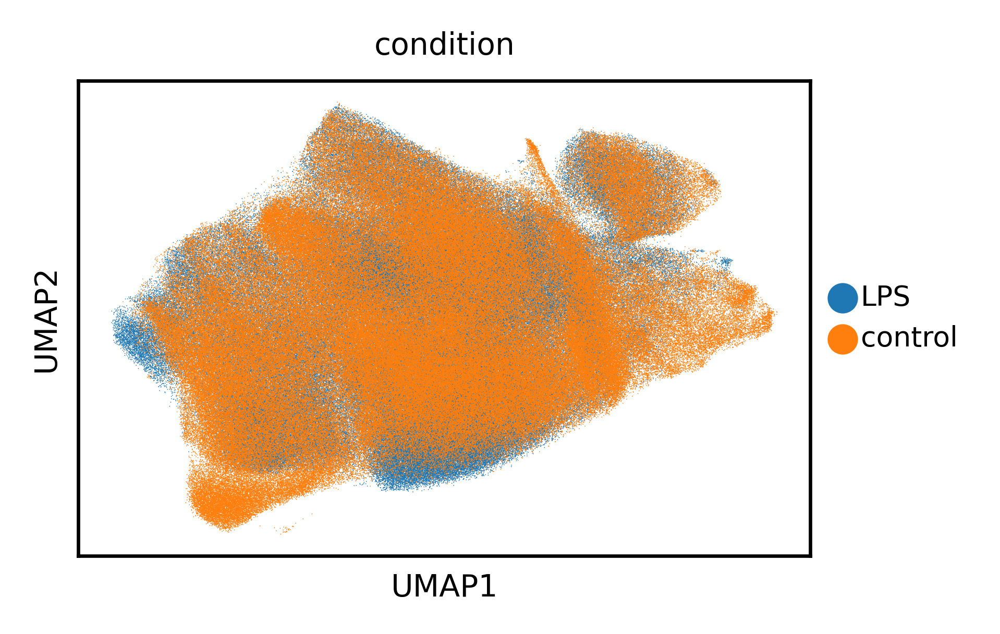

"\n# Cell embedding UMAP\nsc.pp.neighbors(adata,\n                n_neighbors=15,\n                use_rep='cell_emb0',\n                key_added='cell')\nsc.tl.umap(adata,\n           neighbors_key='cell',)\nadata.obsm['cell_umap'] = adata.obsm['X_umap'].copy()\nsc.pl.umap(adata,\n           neighbors_key='cell',\n           color='broad_cell_type')\nsc.pl.umap(adata,\n           neighbors_key='cell',\n           color='cell_type')\nsc.pl.umap(adata,\n           neighbors_key='neighborhood',\n           color='batch')\n"

In [394]:
# Neighborhood embedding UMAP
'''
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb0',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood',)
adata.obsm['neighborhood_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='broad_cell_type')
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='cell_type')
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='batch')
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='condition')

'''
# Spatial embedding UMAP

sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='spatial_cell_emb0',
                key_added='spatial_cell')
sc.tl.umap(adata,
           neighbors_key='spatial_cell',
           )
adata.obsm['spatial_cell_umap'] = adata.obsm['X_umap'].copy()

sc.pl.umap(adata,
           color='broad_cell_type')
sc.pl.umap(adata,
           color='cell_type')
sc.pl.umap(adata,
           color='batch')
sc.pl.umap(adata,
           color='condition')

'''
# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb0',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell',)
adata.obsm['cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='cell',
           color='broad_cell_type')
sc.pl.umap(adata,
           neighbors_key='cell',
           color='cell_type')
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='batch')
'''

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


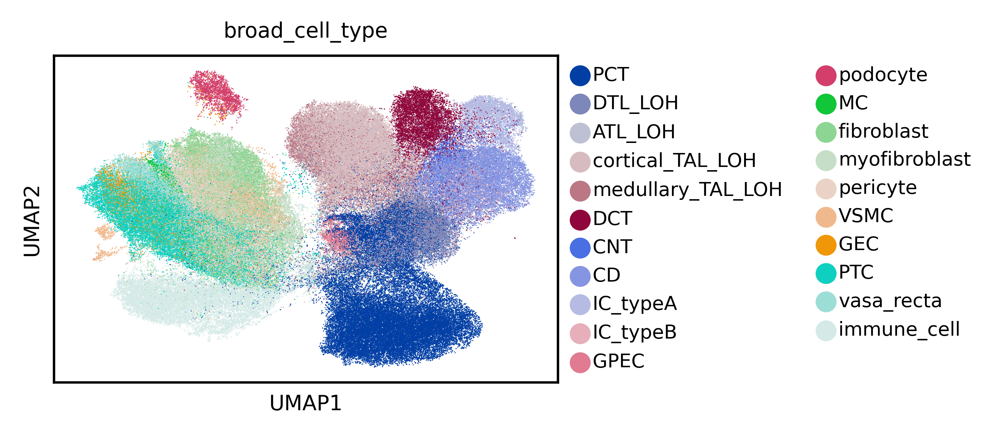

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


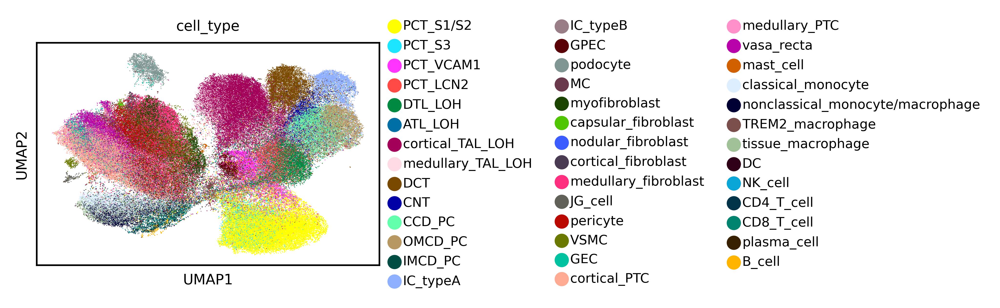

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


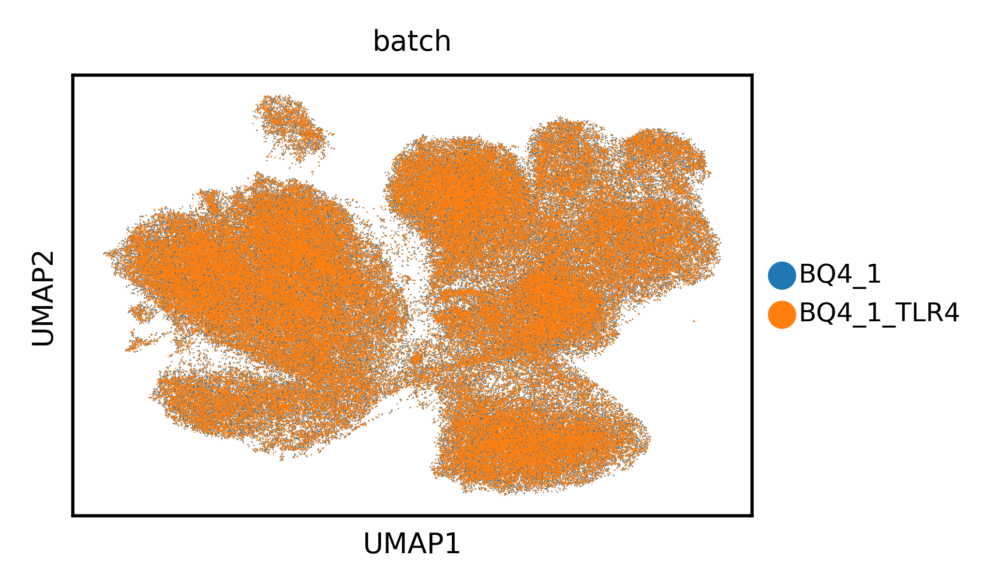

In [553]:
# Neighborhood embedding UMAP
'''

sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb0',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood',)
adata.obsm['neighborhood_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='broad_cell_type')
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='cell_type')
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='batch')
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='condition')

# Spatial embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='spatial_cell_emb0',
                key_added='spatial_cell')
sc.tl.umap(adata,
           neighbors_key='spatial_cell',
           )
adata.obsm['spatial_cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='spatial_cell',
           color='broad_cell_type')
sc.pl.umap(adata,
           neighbors_key='spatial_cell',
           color='cell_type')
'''
# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb0',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell',)
adata.obsm['cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           color='broad_cell_type')
sc.pl.umap(adata,
           color='cell_type')
sc.pl.umap(adata,
           color='batch')

In [606]:
import numpy as np
import pandas as pd

def avg_cosine_by_celltype(
    adata,
    obsm_key: str,
    batch1: str,
    batch2: str,
    batch_col: str = 'batch',
    celltype_col: str = 'cell_type'
) -> pd.DataFrame:
    """
    For each cell_type in adata.obs[celltype_col]:
      – take embeddings from obsm_key for batch1 vs. batch2
      – compute all pairwise cosine similarities between those two sets
      – average them (excluding empty)
      – record the total number of cells of that type (across both batches)
    Returns a DataFrame sorted by descending avg_cosine, with columns:
      ['cell_type', 'n_cells', 'avg_cosine']
    """
    # 1) pull embeddings and obs
    X   = adata.obsm[obsm_key]            # shape (N, D)
    obs = adata.obs[[batch_col, celltype_col]]
    N, D = X.shape

    # 2) normalize embeddings for cosine
    norms = np.linalg.norm(X, axis=1, keepdims=True).clip(min=1e-8)
    Xn = X / norms

    results = []
    # get each unique cell_type
    for ct in tqdm(obs[celltype_col].unique()):
        mask_ct  = (obs[celltype_col] == ct).to_numpy()
        mask_b1  = mask_ct & (obs[batch_col] == batch1).to_numpy()
        mask_b2  = mask_ct & (obs[batch_col] == batch2).to_numpy()

        idx1 = np.nonzero(mask_b1)[0]
        idx2 = np.nonzero(mask_b2)[0]
        n_total = mask_ct.sum()

        # skip if either batch missing
        if idx1.size == 0 or idx2.size == 0:
            continue

        # embeddings
        E1 = Xn[idx1]   # (n1, D)
        E2 = Xn[idx2]   # (n2, D)

        # pairwise cosine sim and average
        sims = E1 @ E2.T       # (n1, n2)
        avg  = sims.mean()

        results.append({
            'cell_type':   ct,
            'n_cells':     int(n_total)/2,
            'avg_cosine':  float(avg)
        })

    df = pd.DataFrame(results)
    return df.sort_values('avg_cosine', ascending=False).reset_index(drop=True)


In [624]:
import numpy as np
import pandas as pd

def mean_embedding_cosine(
    adata,
    obsm_key: str,
    batch1: str,
    batch2: str,
    batch_col: str = 'batch',
    celltype_col: str = 'cell_type',
    eps: float = 1e-8
) -> pd.DataFrame:
    """
    For each cell type in adata.obs[celltype_col]:
      • compute the mean embedding (adata.obsm[obsm_key]) for cells in batch1
      • compute the mean embedding for cells in batch2
      • compute the cosine similarity between those two mean vectors
    Returns a DataFrame with columns ['cell_type', 'avg_cosine'], sorted descending.
    """
    # pull out the embedding matrix and metadata
    X   = adata.obsm[obsm_key]               # (N, D)
    obs = adata.obs[[batch_col, celltype_col]]

    results = []
    for ct in obs[celltype_col].unique():
        # boolean masks
        is_ct = (obs[celltype_col] == ct).to_numpy()
        idx1  = np.nonzero(is_ct & (obs[batch_col] == batch1).to_numpy())[0]
        idx2  = np.nonzero(is_ct & (obs[batch_col] == batch2).to_numpy())[0]

        # skip types missing in either batch
        if idx1.size == 0 or idx2.size == 0:
            continue

        # mean embeddings per condition
        n_total =  X[idx1].shape[0] +  X[idx2].shape[0]
        m1 = X[idx1].mean(axis=0)
        m2 = X[idx2].mean(axis=0)

        # cosine similarity
        num = np.dot(m1, m2)
        den = (np.linalg.norm(m1) * np.linalg.norm(m2)) + eps
        cos = num / den

        results.append({'cell_type': ct, 'avg_cosine': float(cos),'n_cells':int(n_total)/2})

    df = pd.DataFrame(results)
    return df.sort_values('avg_cosine', ascending=False).reset_index(drop=True)


In [899]:
out_dfg_3 = mean_embedding_cosine(adata,'cell_emb0','BQ4_1','BQ4_1_TLR4')

In [904]:
out_dfg_3.sort_values(by='avg_cosine').equals(out_dfg_1.sort_values(by='avg_cosine'))

True

In [626]:
out_dfg_1 = mean_embedding_cosine(adata,'cell_emb0','BQ4_1','BQ4_1_TLR4')

In [627]:
out_dfg_1.sort_values(by='avg_cosine')

,cell_type,avg_cosine,n_cells
40,medullary_PTC,0.999884,2343.0
39,nonclassical_monocyte/macrophage,0.999918,2256.0
38,classical_monocyte,0.999952,3496.0
37,vasa_recta,0.999967,4459.0
36,pericyte,0.999968,5893.0
35,MC,0.999976,1831.0
34,GEC,0.999978,2923.0
33,myofibroblast,0.999980,5963.0
32,cortical_PTC,0.999981,9742.0
31,tissue_macrophage,0.999987,1917.0


In [905]:
out_dfg2_new = avg_cosine_by_celltype(adata,'cell_emb0','BQ4_1','BQ4_1_TLR4')

100%|██████████| 41/41 [00:04<00:00,  8.49it/s]


In [907]:
out_dfg2_new.sort_values(by='avg_cosine').equals(out_dfg2.sort_values(by='avg_cosine'))

False

In [909]:
out_dfg2_new.sort_values(by='avg_cosine')

,cell_type,n_cells,avg_cosine
40,TREM2_macrophage,1075.0,0.475557
39,plasma_cell,112.0,0.520565
38,PCT_S3,1966.0,0.533197
37,ATL_LOH,331.0,0.542073
36,myofibroblast,5963.0,0.560781
35,DTL_LOH,5833.0,0.580934
34,PCT_LCN2,4166.0,0.581583
33,CD8_T_cell,1090.0,0.586519
32,PCT_S1/S2,17519.0,0.587353
31,cortical_TAL_LOH,18072.0,0.588377


In [630]:
out_dfg2.sort_values(by='avg_cosine')

,cell_type,n_cells,avg_cosine
40,TREM2_macrophage,1075.0,0.475758
39,plasma_cell,112.0,0.520672
38,PCT_S3,1966.0,0.533205
37,ATL_LOH,331.0,0.542093
36,myofibroblast,5963.0,0.561005
35,DTL_LOH,5833.0,0.580908
34,PCT_LCN2,4166.0,0.581551
33,CD8_T_cell,1090.0,0.586659
32,PCT_S1/S2,17519.0,0.587389
31,cortical_TAL_LOH,18072.0,0.588396


In [607]:
out_dfg = avg_cosine_by_celltype(adata,'cell_emb0','BQ4_1','BQ4_1_TLR4')

100%|██████████| 41/41 [00:02<00:00, 15.57it/s]


In [617]:
out_dfg.sort_values(by='avg_cosine')

,cell_type,n_cells,avg_cosine
40,TREM2_macrophage,1075.0,0.475557
39,plasma_cell,112.0,0.520565
38,PCT_S3,1966.0,0.533197
37,ATL_LOH,331.0,0.542073
36,myofibroblast,5963.0,0.560781
35,DTL_LOH,5833.0,0.580934
34,PCT_LCN2,4166.0,0.581583
33,CD8_T_cell,1090.0,0.586519
32,PCT_S1/S2,17519.0,0.587353
31,cortical_TAL_LOH,18072.0,0.588377


In [632]:
out_dfg["avg_cosine_diff"] = out_dfg2["avg_cosine"] - out_dfg["avg_cosine"]     # difference
out_dfg.sort_values("avg_cosine_diff", ascending=False)  # sort (largest first)


,cell_type,n_cells,avg_cosine,avg_cosine_diff
21,nonclassical_monocyte/macrophage,2256.0,0.638086,0.000851
30,medullary_PTC,2343.0,0.592439,0.000585
14,classical_monocyte,3496.0,0.659514,0.000455
16,pericyte,5893.0,0.652222,0.000310
36,myofibroblast,5963.0,0.560781,0.000224
40,TREM2_macrophage,1075.0,0.475557,0.000200
12,cortical_PTC,9742.0,0.668789,0.000188
28,CD4_T_cell,1325.0,0.600708,0.000176
13,tissue_macrophage,1917.0,0.662116,0.000168
33,CD8_T_cell,1090.0,0.586519,0.000141


In [596]:
ct = 'GEC'
adata.obs['cell_type'].unique()
mask_ct  = (adata.obs['cell_type'] == ct).to_numpy()
mask_b1  = mask_ct & (adata.obs['batch'] == 'BQ4_1').to_numpy()
mask_b2  = mask_ct & (adata.obs['batch'] == 'BQ4_1_TLR4').to_numpy()
idx1 = np.nonzero(mask_b1)[0]
idx2 = np.nonzero(mask_b2)[0]
n_total = mask_ct.sum()


In [597]:
E1 = Xn[idx1]   # (n1, D)
E2 = Xn[idx2]   # (n2, D)

# pairwise cosine sim and average
sims = E1 @ E2.T       # (n1, n2)
avg  = sims.mean()


In [ ]:
avg

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


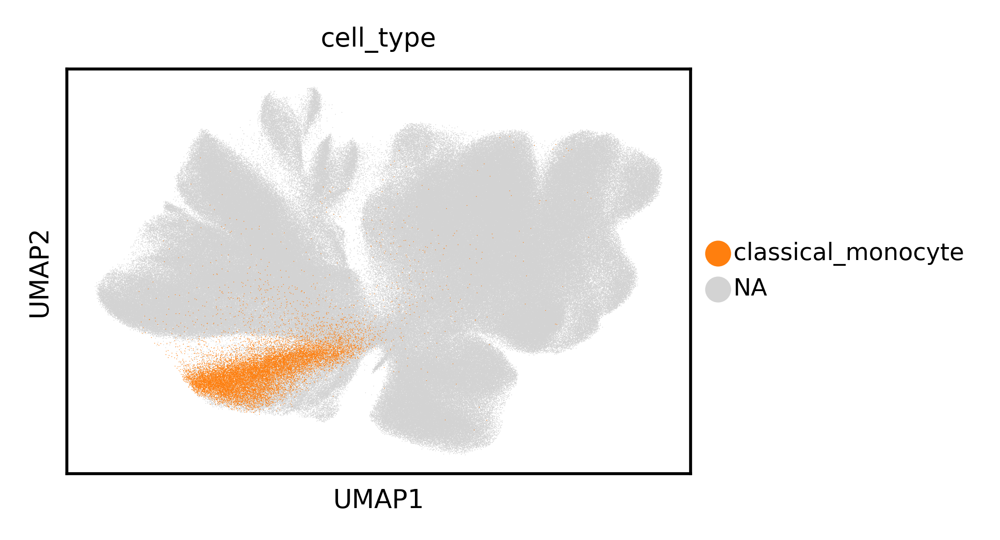

In [390]:
sc.pl.umap(
    adata,
    color='cell_type',
    neighbors_key='cell',
    groups=['classical_monocyte'],  # only these will be colored
    palette=['#1f77b4', '#ff7f0e']  # optional: choose colors for them
)


In [ ]:
adata.obs

In [328]:
adata.write("/nfs/team361/mv10/andata_res/LPS_BQ4_1.h5ad")

In [348]:
adata.write("/nfs/team361/mv10/andata_res/LPS_BQ6_1.h5ad")

In [380]:
adata.write("/nfs/team361/mv10/andata_res/LPS_BQ6_2.h5ad")

In [364]:
adata.write("/nfs/team361/mv10/andata_res/LPS_BQ4_2.h5ad")

In [895]:
adata.write("/nfs/team361/mv10/andata_res/LPS_1_BQ4_ENSG00000136869_TLR4.h5ad")

In [896]:
adata_BQ4_1 = sc.read_h5ad("/nfs/team361/mv10/andata_res/LPS_BQ4_1.h5ad")
#adata_BQ6_1 = sc.read_h5ad("/nfs/team361/mv10/andata_res/LPS_BQ6_1.h5ad")
#adata_BQ4_2 = sc.read_h5ad("/nfs/team361/mv10/andata_res/LPS_BQ4_2.h5ad")
#adata_BQ6_2 = sc.read_h5ad("/nfs/team361/mv10/andata_res/LPS_BQ6_2.h5ad")
#adata_BQ4_1_TLR4 = sc.read_h5ad("/nfs/team361/mv10/andata_res/LPS_BQ4_ENSG00000136869_TLR4.h5ad")
adata_BQ4_1_TLR4 = sc.read_h5ad('/nfs/team361/mv10/andata_res/LPS_1_BQ4_ENSG00000136869_TLR4.h5ad')

In [107]:
adata = sc.read_h5ad("/nfs/team361/mv10/andata_res/LPS_BQ4_1.h5ad")


In [897]:
adata = ad.concat([adata_BQ4_1, adata_BQ4_1_TLR4], join="outer", 
                  label="batch", keys=["BQ4_1", "BQ4_1_TLR4"])


/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [392]:
adata = ad.concat([adata_BQ4_1, adata_BQ6_1, adata_BQ4_2, adata_BQ6_2], join="outer", label="batch", keys=["BQ4_1", "BQ6_1", 'BQ4_2', 'BQ6_2'])


/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


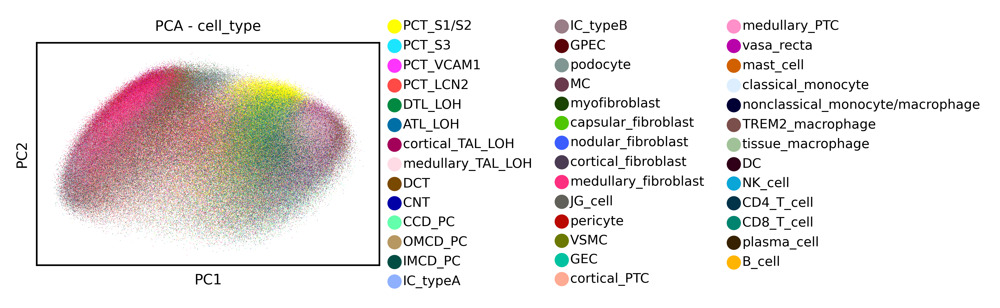

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


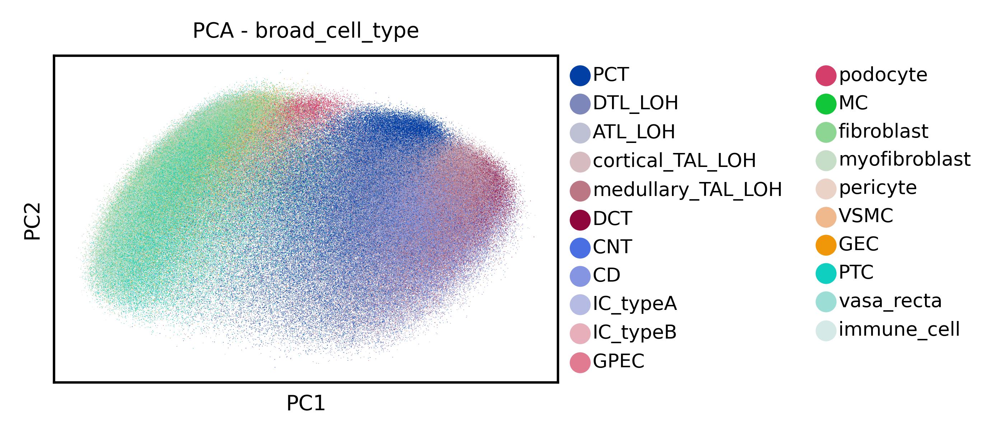

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


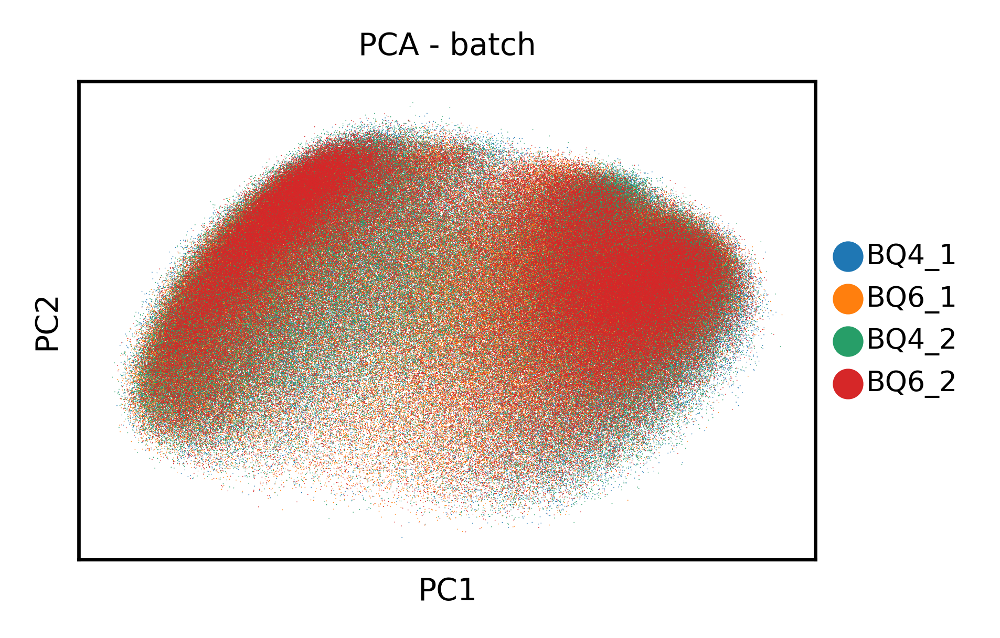

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


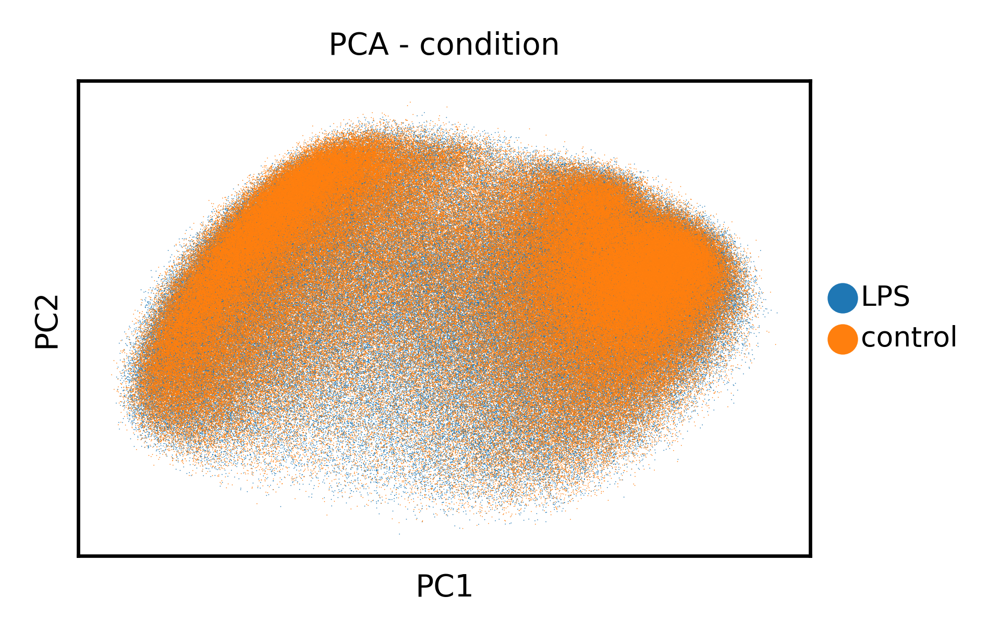

In [214]:
# Step 1: Create a temporary AnnData object for PCA on cell_emb0
adata_temp = ad.AnnData(X=adata.obsm['cell_emb0'])
adata_temp.obs = adata.obs[['cell_type', 'broad_cell_type', 'batch', 'condition']].copy()

# Step 2: Run PCA
sc.pp.pca(adata_temp, n_comps=50)

# Step 3: Visualize PCA colored by different annotations
sc.pl.pca(adata_temp, color='cell_type', title='PCA - cell_type')
sc.pl.pca(adata_temp, color='broad_cell_type', title='PCA - broad_cell_type')
sc.pl.pca(adata_temp, color='batch', title='PCA - batch')
sc.pl.pca(adata_temp, color='condition', title='PCA - condition')


/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


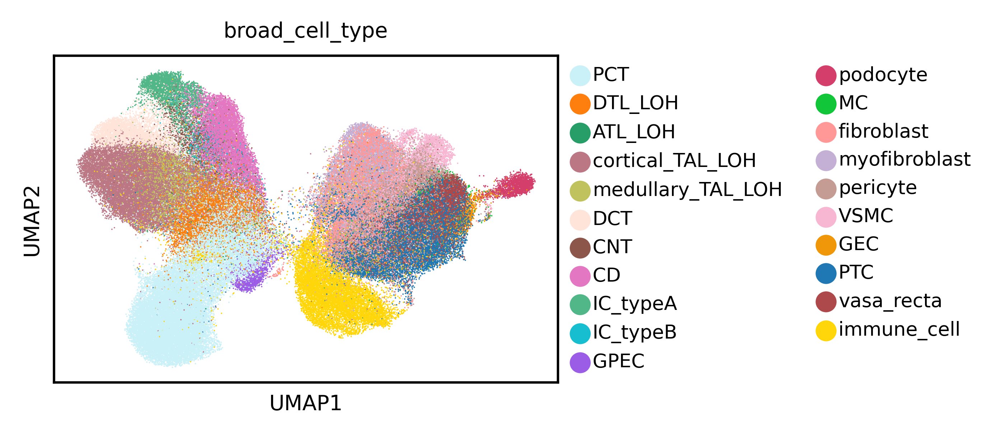

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


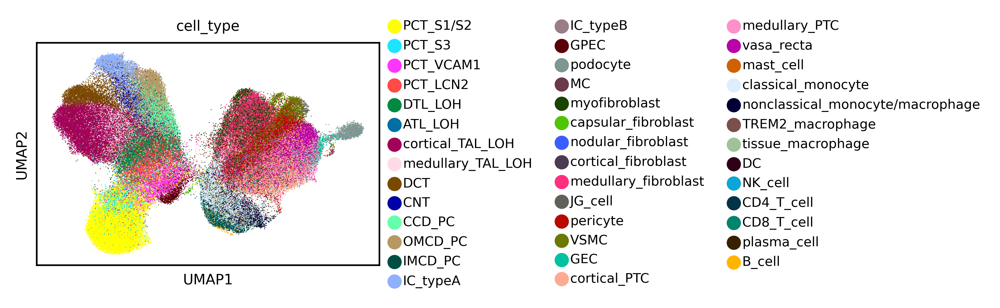

In [88]:
# Neighborhood embedding UMAP
'''
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb{emb_layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood',
           key_added='neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color=label)

# Spatial embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'spatial_cell_emb{emb_layer}',
                key_added='spatial_cell')
sc.tl.umap(adata,
           neighbors_key='spatial_cell',
           key_added='spatial_cell_umap')
adata.obsm['X_umap'] = adata.obsm['spatial_cell_umap']
sc.pl.umap(adata,
           neighbors_key='spatial_cell',
           color=label)
'''
# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb0',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell',)
adata.obsm['cell_umap'] = adata.obsm['X_umap'].copy()
sc.pl.umap(adata,
           neighbors_key='cell',
           color='broad_cell_type')
sc.pl.umap(adata,
           neighbors_key='cell',
           color='cell_type')

In [92]:
import numpy as np
from numpy.linalg import norm

# Extract embeddings from AnnData object
A = adata.obsm[f'neighborhood_emb{emb_layer}']
B = adata.obsm[f'spatial_cell_emb{emb_layer}']

# Normalize each row to unit vectors
A_norm = A / norm(A, axis=1, keepdims=True)
B_norm = B / norm(B, axis=1, keepdims=True)

# Compute cosine similarities between matching rows
cosine_similarities = np.sum(A_norm * B_norm, axis=1)

adata.obs[f'neighborhood{emb_layer}_spatial_cell{emb_layer}_cos_sim'] = cosine_similarities

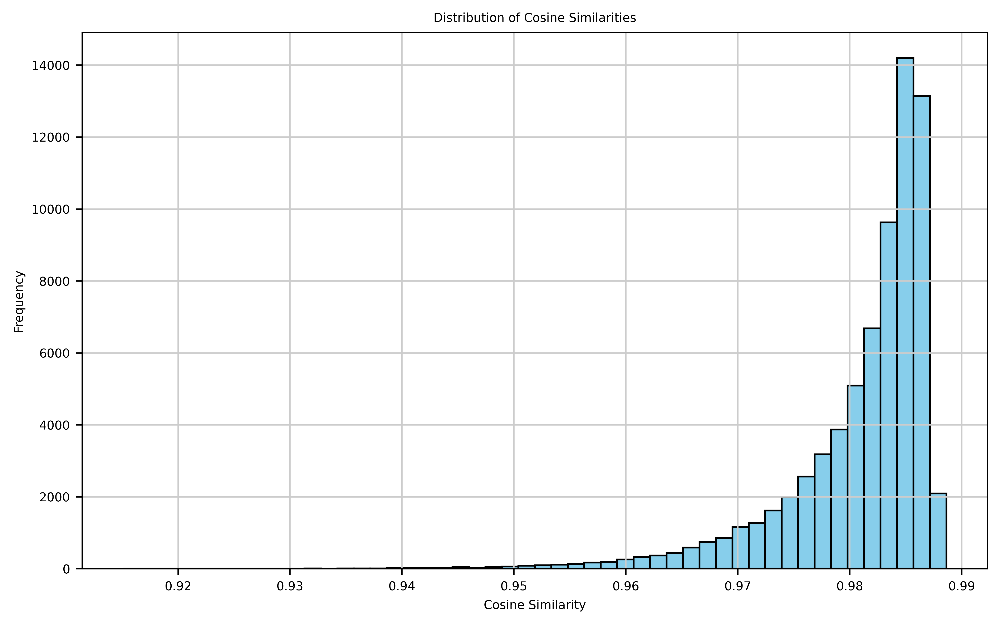

In [93]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(adata.obs['neighborhood1_spatial_cell1_cos_sim'], bins=50, color='skyblue', edgecolor='black')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.title('Distribution of Cosine Similarities')
plt.grid(True)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1788776/2083551480.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


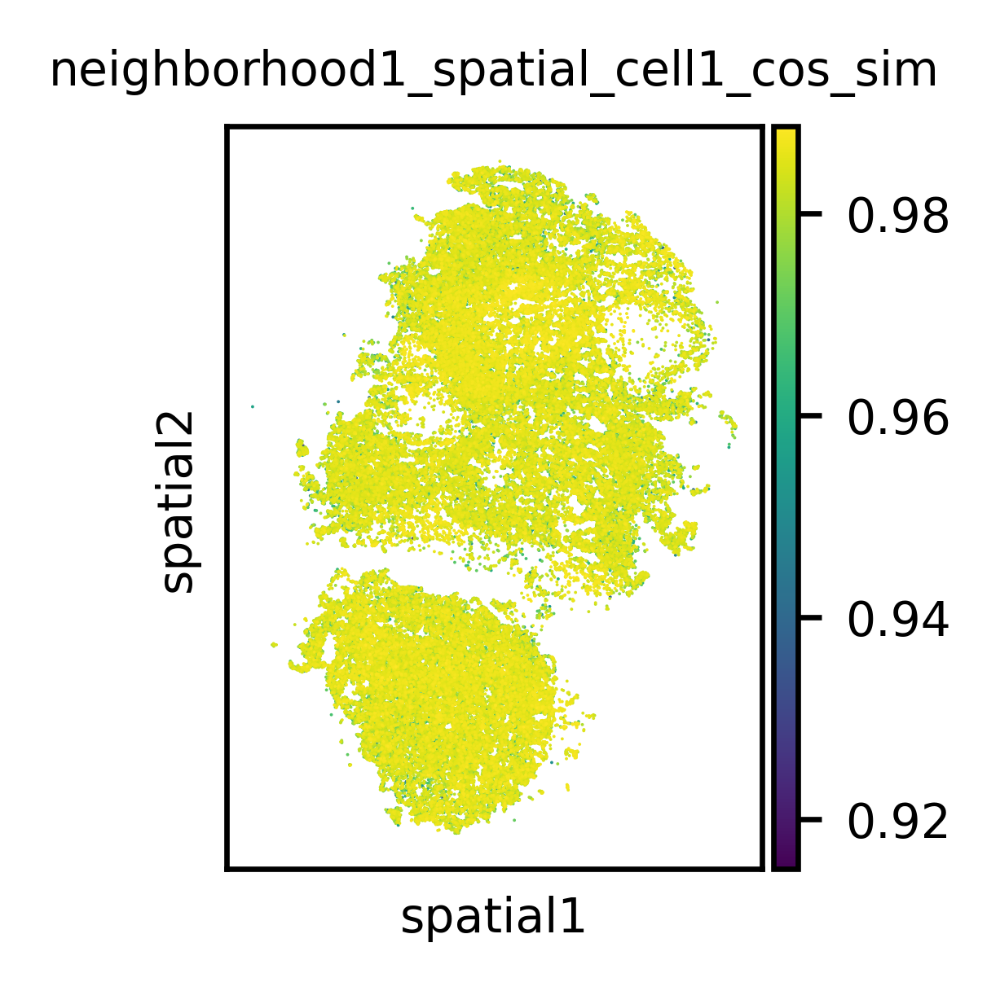

In [68]:
sc.pl.spatial(
    adata,
    color='neighborhood1_spatial_cell1_cos_sim',
    spot_size=30)  

In [25]:
adata.obsm['cell_emb'] = output_embed['cell_emb']
adata.obsm['spatial_cell_emb'] = output_embed['spatial_cell_emb']
adata.obsm['neighborhood_emb'] = output_embed['neighborhood_emb']

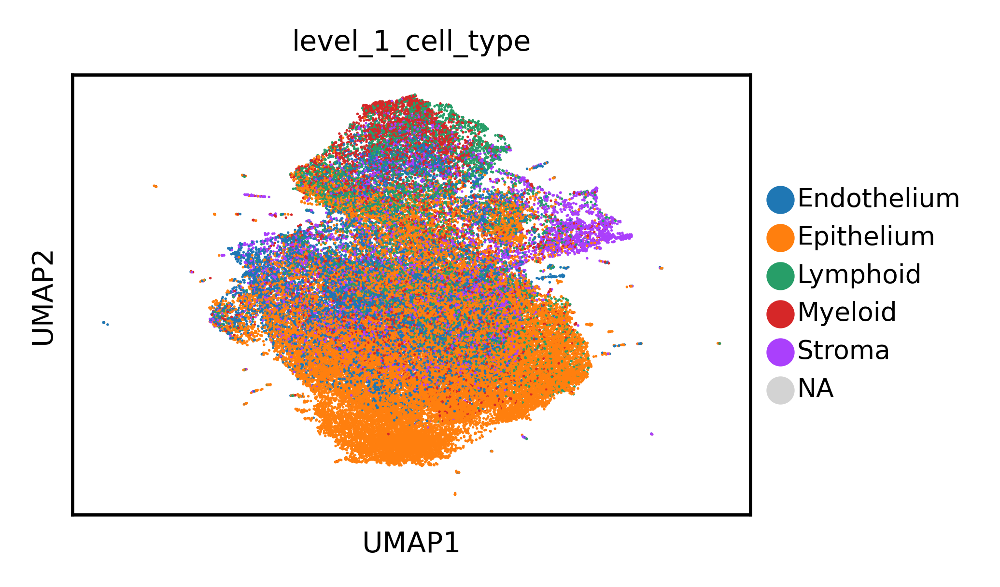

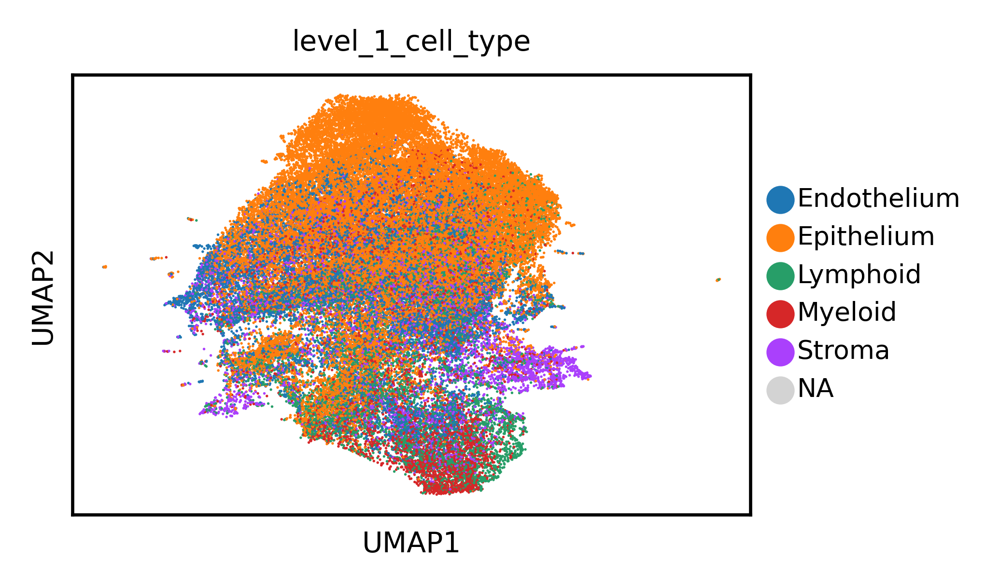

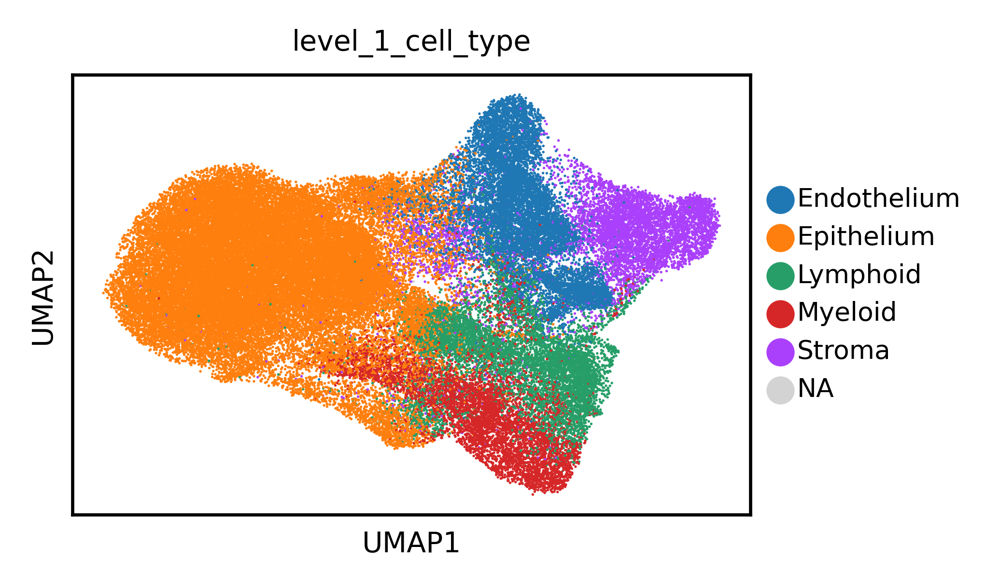

In [26]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood',
           key_added='neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color=label)

# Spatial embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='spatial_cell_emb',
                key_added='spatial_cell')
sc.tl.umap(adata,
           neighbors_key='spatial_cell',
           key_added='spatial_cell_umap')
adata.obsm['X_umap'] = adata.obsm['spatial_cell_umap']
sc.pl.umap(adata,
           neighbors_key='spatial_cell',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell',
           key_added='cell_umap')
adata.obsm['X_umap'] = adata.obsm['cell_umap']
sc.pl.umap(adata,
           neighbors_key='cell',
           color=label)

In [41]:
import numpy as np
from numpy.linalg import norm

# Extract embeddings from AnnData object
A = adata.obsm['neighborhood_emb']
B = adata.obsm['spatial_cell_emb']

# Normalize each row to unit vectors
A_norm = A / norm(A, axis=1, keepdims=True)
B_norm = B / norm(B, axis=1, keepdims=True)

# Compute cosine similarities between matching rows
cosine_similarities = np.sum(A_norm * B_norm, axis=1)

adata.obs['neighborhood_spatial_cell_cos_sim'] = cosine_similarities

/tmp/ipykernel_1788776/3157216358.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


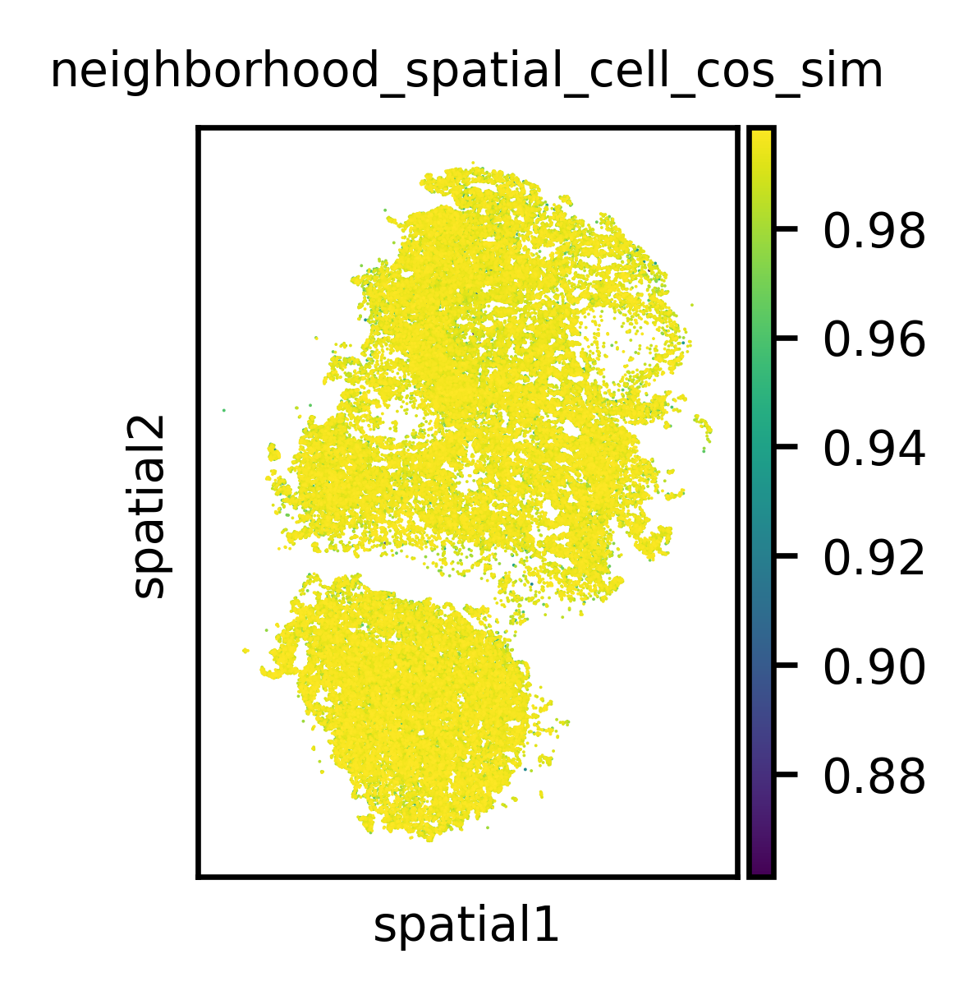

In [44]:
sc.pl.spatial(
    adata,
    color='neighborhood_spatial_cell_cos_sim',
    spot_size=30)  

In [39]:
len(cosine_similarities)

71118

#### 2.1.5 Perturbed Data

In [27]:
pert_cell_id_file_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/data/macrophage_TLS_cell_names.txt'

with open(pert_cell_id_file_path, 'r') as file:
    pert_cell_id = [line.strip() for line in file]

In [28]:
adata.obs['pert_cell_id'] = adata.obs['original_cell_id'].apply(lambda x: x in pert_cell_id)

/tmp/ipykernel_1788776/547068047.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


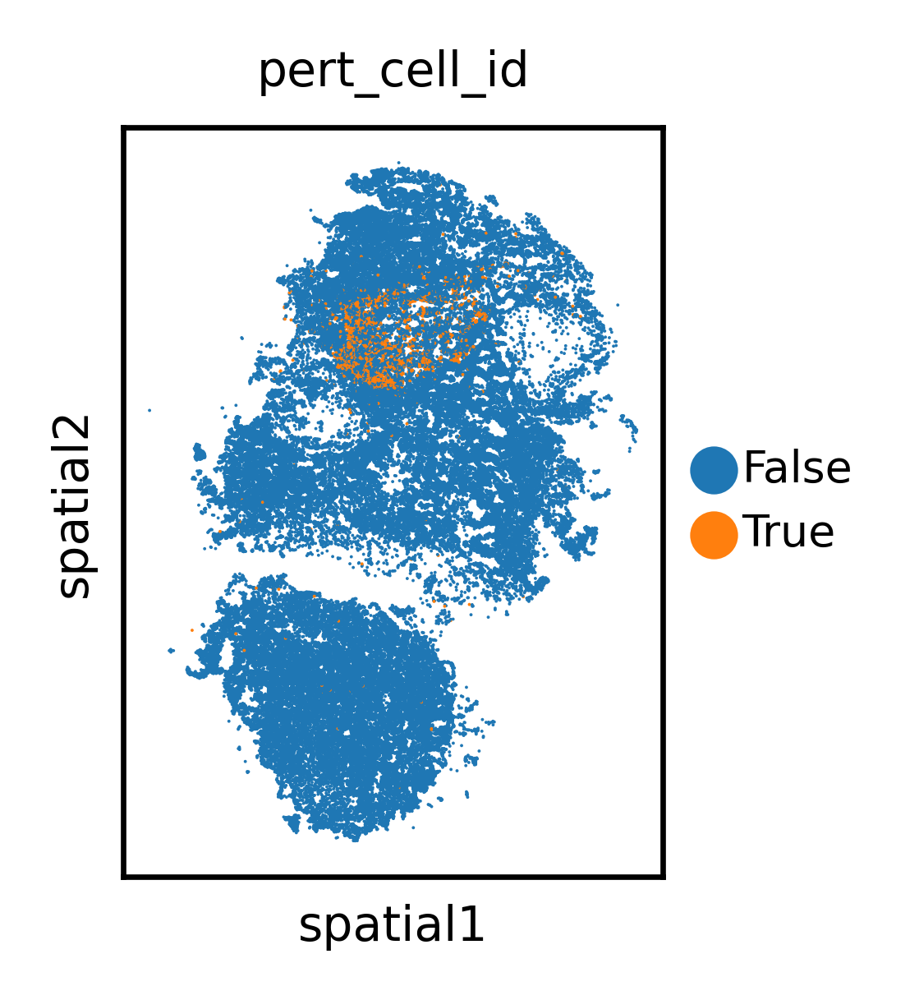

In [29]:
sc.pl.spatial(
    adata,
    color='pert_cell_id',
    spot_size=30)  

In [395]:
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 192166
})

In [ ]:
adata_BQ4_1.var

In [413]:
adata_BQ4_1.var[adata_BQ4_1.var['ensembl_id']=='ENSG00000111537']

,ensembl_id
gene_name,
IFNG,ENSG00000111537


In [403]:
import pickle

In [404]:
path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/18062025_082526_412/token_dictionary.pkl'

# Load the dictionary
with open(path, 'rb') as f:
    token_dict = pickle.load(f)


In [ ]:
token_dict['ENSG00000111537']

In [ ]:
perturbed_cell_id = adata_BQ4_1.obs['cell_id'].tolist() # ['1007_batch20_0', '1007_batch20_0', '1007_batch20_1']
perturbed_ensembl_id = ['ENSG00000136869'] * len(perturbed_cell_id)
perturbation_target = ['cell'] * len(perturbed_cell_id)
perturbation_type = ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan] * len(perturbed_cell_id)
perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})
perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path)

In [9]:
cell_ids = dataset['cell_id']

In [114]:
cell_ids==adata.obs['cell_id'].to_list()

True

In [109]:
len(adata.obs['cell_id'].to_list())

140491

In [176]:
len(cell_ids)

140491

In [924]:
perturb_df[perturb_df['perturbed_cell_id']=='aaaagajo-1']

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,aaaagajo-1,ENSG00000136869,cell,knockout,NaN
140491,aaaagajo-1,ENSG00000111537,cell,knockout,NaN


In [51]:
perturbed_cell_id = cell_ids + cell_ids# ['1007_batch20_0', '1007_batch20_0', '1007_batch20_1']
perturbed_ensembl_id = ['ENSG00000136869'] * len(cell_ids) + ['ENSG00000111537'] * len(cell_ids) 
perturbation_target = ['cell'] * len(cell_ids) + ['cell'] * len(cell_ids)
perturbation_type = ['knockout'] * len(cell_ids) + ['knockout'] * len(cell_ids)
foldchange = [np.nan] * len(cell_ids) + [np.nan] * len(cell_ids)



In [49]:
perturb_df

,perturbed_cell_id,perturbed_ensembl_id,perturbation_target,perturbation_type,foldchange
0,aaaagajo-1,ENSG00000111537,neighborhood,knockout,NaN
1,aaabhjmp-1,ENSG00000111537,neighborhood,knockout,NaN
2,aaadbhjf-1,ENSG00000111537,neighborhood,knockout,NaN
3,aaaedeoo-1,ENSG00000111537,neighborhood,knockout,NaN
4,aaaekckf-1,ENSG00000111537,neighborhood,knockout,NaN
...,...,...,...,...,...
280977,oimnpjgd-1,ENSG00000136869,neighborhood,knockout,NaN
280978,oimodace-1,ENSG00000136869,neighborhood,knockout,NaN
280979,oimplpgb-1,ENSG00000136869,neighborhood,knockout,NaN
280980,oimpnbkc-1,ENSG00000136869,neighborhood,knockout,NaN


In [47]:
import datasets


In [83]:
datasets.disable_caching()

In [ ]:
datasets.enable_caching()


In [30]:
perturbed_dataset1 = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path,
    batch_size=1000,
    nproc=1)

Map:   0%|          | 0/140491 [00:00<?, ? examples/s]

In [23]:
import psutil, os, signal
for p in psutil.Process().children(recursive=True):
    try:
        p.kill()
    except Exception:
        pass


In [53]:
perturbed_dataset1

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 140491
})

In [26]:
model_folder_path

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/18062025_082526_412'

In [32]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    include_spatial_cell_emb=True)

STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
556it [10:54,  1.18s/it]


In [33]:
adata.obsm['cell_emb_pert'] = perturbed_output_embed['cell_emb']
adata.obsm['spatial_cell_emb_pert'] = perturbed_output_embed['spatial_cell_emb']
adata.obsm['neighborhood_emb_pert'] = perturbed_output_embed['neighborhood_emb']

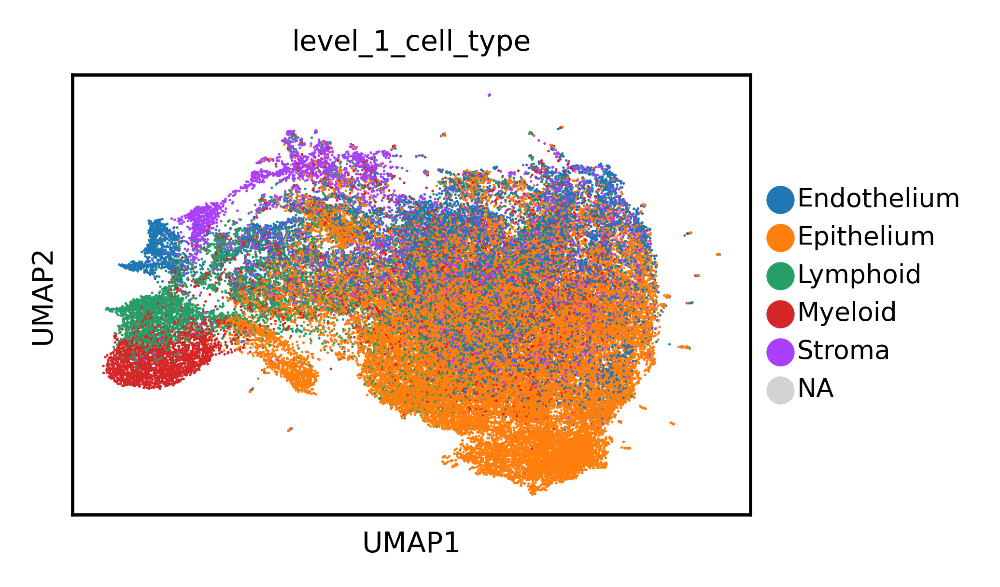

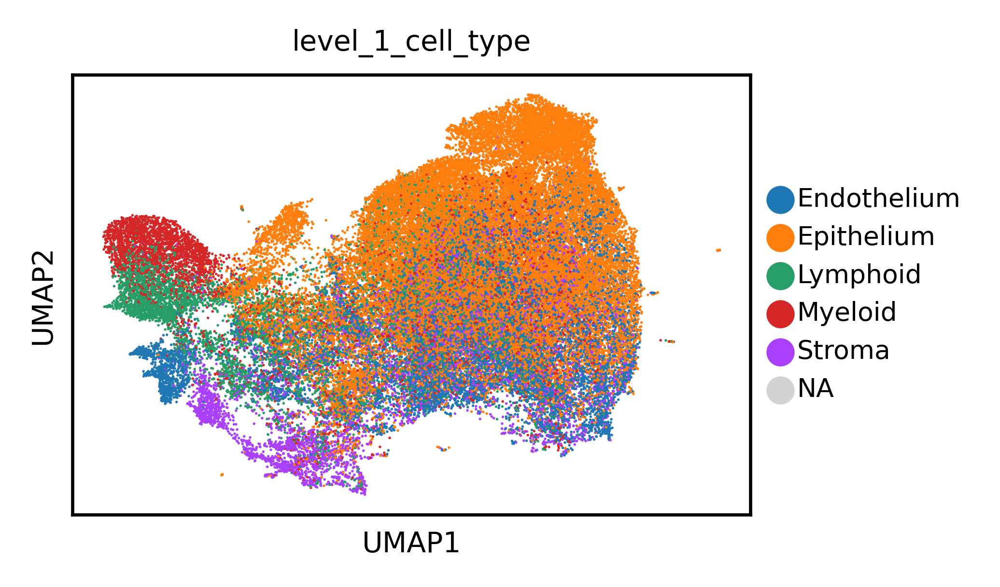

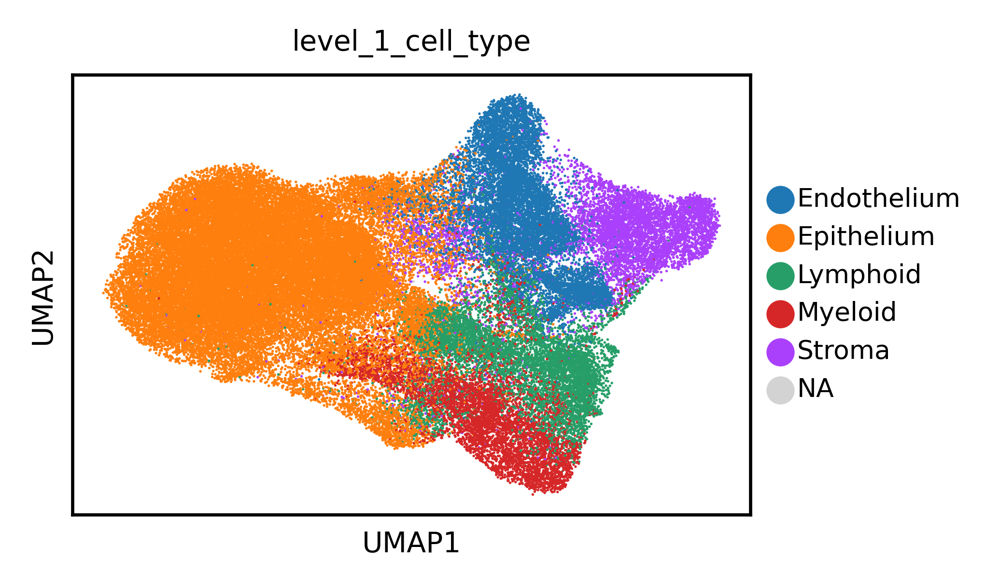

In [34]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='neighborhood_emb_pert',
                key_added='neighborhood_pert')
sc.tl.umap(adata,
           neighbors_key='neighborhood_pert',
           key_added='neighborhood_umap_pert')
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap_pert']
sc.pl.umap(adata,
           neighbors_key='neighborhood_pert',
           color=label)

sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='spatial_cell_emb_pert',
                key_added='spatial_cell_pert')
sc.tl.umap(adata,
           neighbors_key='spatial_cell_pert',
           key_added='spatial_cell_umap_pert')
adata.obsm['X_umap'] = adata.obsm['spatial_cell_umap_pert']
sc.pl.umap(adata,
           neighbors_key='spatial_cell_pert',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='cell_emb_pert',
                key_added='cell_pert')
sc.tl.umap(adata,
           neighbors_key='cell_pert',
           key_added='cell_umap_pert')
adata.obsm['X_umap'] = adata.obsm['cell_umap_pert']
sc.pl.umap(adata,
           neighbors_key='cell_pert',
           color=label)

In [ ]:
perturbed = adata.obs['pert_cell_id'].values.astype(bool)

connectivity_matrix = adata.obsp['spatial_connectivities'].tocsr()

# Multiply the connectivity matrix with the perturbed boolean vector
# This computes, for each cell, how many of its neighbors are perturbed
neighbor_perturbed_counts = connectivity_matrix.dot(perturbed)

# If count > 0, it means at least one perturbed neighbor exists
adata.obs['pert_cell_id_in_neighborhood'] = neighbor_perturbed_counts > 0

In [ ]:
adata.obs['pert_cell_id_in_neighborhood'].value_counts()

In [ ]:
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='pert_cell_id')

In [ ]:
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='pert_cell_id_in_neighborhood')

In [ ]:
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap_pert']
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='pert_cell_id')

In [ ]:
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap_pert']
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='pert_cell_id_in_neighborhood')

In [ ]:
adata.obsm['neighborhood_emb'].shape

In [ ]:
adata.obsm['neighborhood_emb_pert'].shape

In [45]:
import numpy as np
from numpy.linalg import norm

# Extract embeddings from AnnData object
A = adata.obsm['spatial_cell_emb']
B = adata.obsm['spatial_cell_emb_pert']

# Normalize each row to unit vectors
A_norm = A / norm(A, axis=1, keepdims=True)
B_norm = B / norm(B, axis=1, keepdims=True)

# Compute cosine similarities between matching rows
adata.obs['spatial_cell_spatial_cell_pert_cos_sim'] = cosine_similarities = np.sum(A_norm * B_norm, axis=1)

/tmp/ipykernel_1788776/1585290786.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


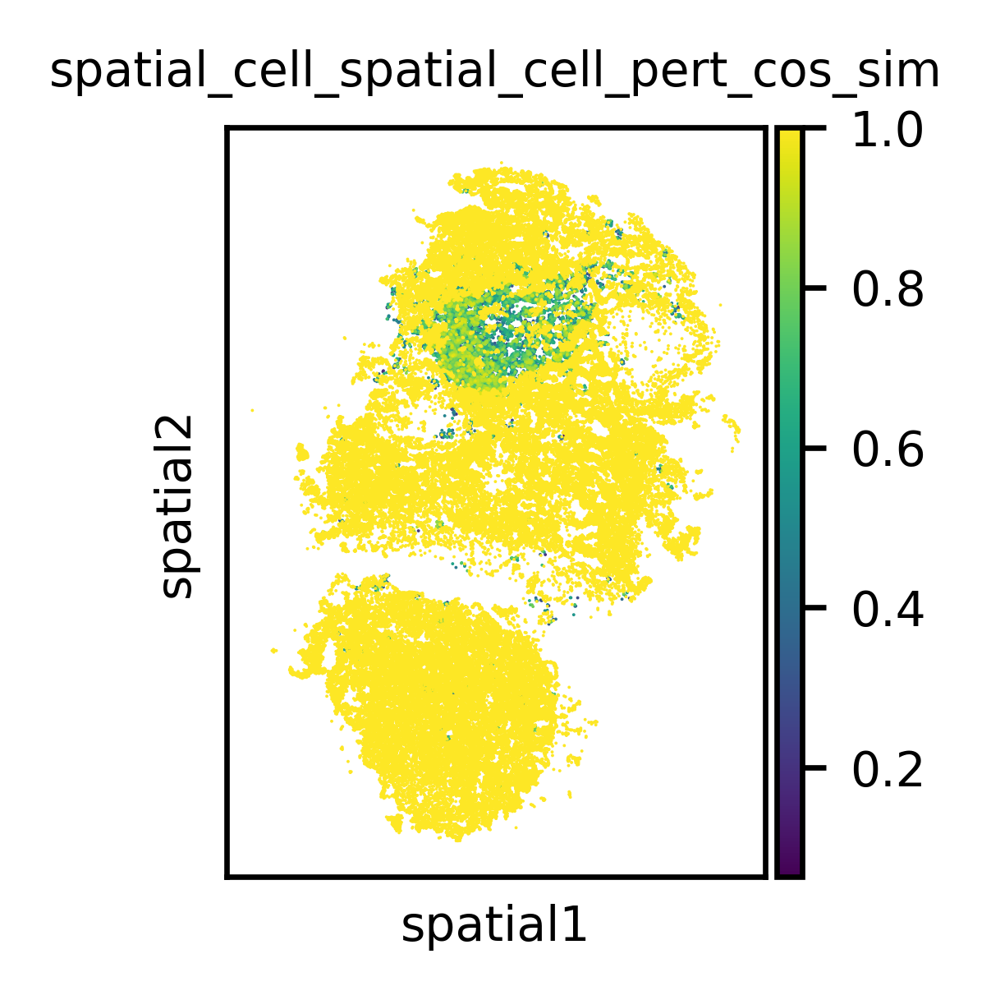

In [47]:
sc.pl.spatial(
    adata,
    color='spatial_cell_spatial_cell_pert_cos_sim',
    spot_size=30)  

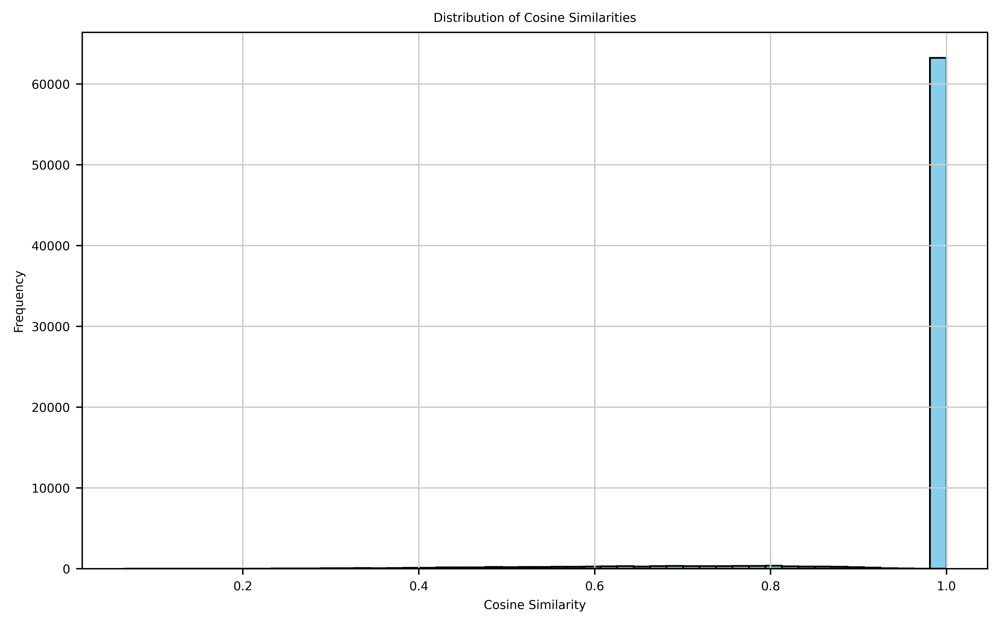

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(cosine_similarities, bins=50, color='skyblue', edgecolor='black')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.title('Distribution of Cosine Similarities')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
unchanged_mask = np.all(np.isclose(A, B, atol=1e-6), axis=1)

In [ ]:
unchanged_mask

In [ ]:
changed_cosine_similarities = cosine_similarities[~unchanged_mask]


In [ ]:
changed_cosine_similarities

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(changed_cosine_similarities, bins=50, kde=True, color='tomato')
plt.xlabel('Cosine Similarity (Changed Only)')
plt.ylabel('Density')
plt.title('Distribution of Cosine Similarities (Excluding Unchanged Rows)')
plt.tight_layout()
plt.show()


In [ ]:
n = 100  # change this to however many lowest you'd like

# Get the indices that would sort the array in ascending order
sorted_indices = np.argsort(cosine_similarities)

# Get the first n indices (lowest similarities)
lowest_n_indices = sorted_indices[:n]

print("Indices of the lowest cosine similarities:", lowest_n_indices)

In [ ]:
len(cosine_similarities)

In [ ]:
lowest_n_indices

In [82]:
# Initialize column with all False
adata.obs['top_cos_sim_change'] = False

# Set True for the specified indices
adata.obs.iloc[lowest_n_indices, adata.obs.columns.get_loc('top_cos_sim_change')] = True


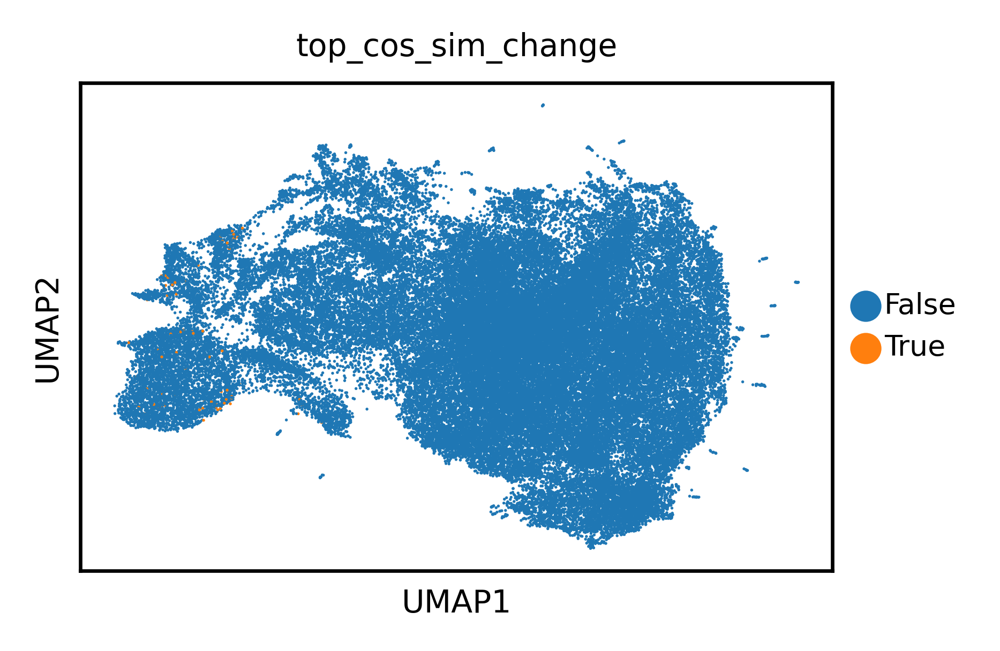

In [83]:
adata.obsm['X_umap'] = adata.obsm['neighborhood_umap_pert']
sc.pl.umap(adata,
           neighbors_key='neighborhood',
           color='top_cos_sim_change')

/tmp/ipykernel_573593/2345172177.py:1: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


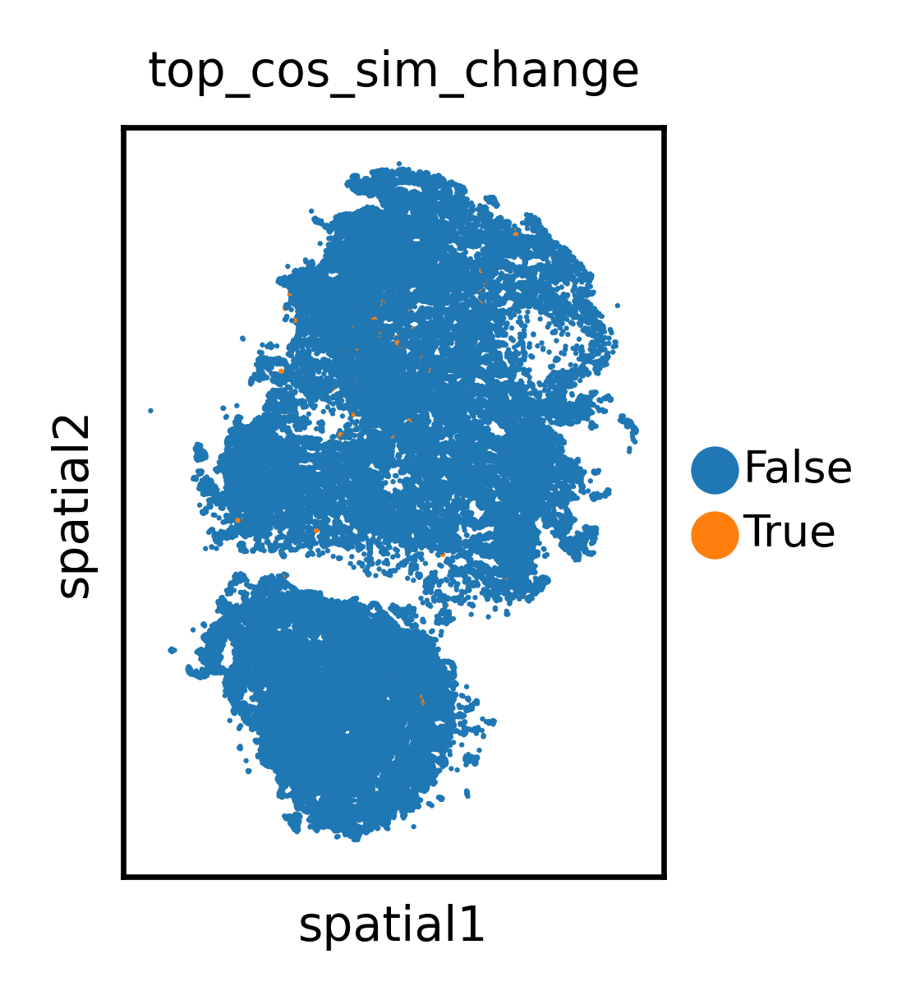

In [86]:
sc.pl.spatial(
    adata,
    color='top_cos_sim_change',
    spot_size=50)   

In [88]:
cell_ids = dataset['cell_ids']

In [ ]:
cell_ids

In [ ]:
adata.obs['top_cos_sim_change']

In [70]:
adata[adata.obs.index.isin(lowest_n_indices)]

View of AnnData object with n_obs × n_vars = 0 × 4949
    obs: 'batch', 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'n_genes', 'original_cell_id', 'level_1_cell_type', 'pert_cell_id'
    var: 'ensembl_id'
    uns: 'assay', 'batch', 'condition', 'dataset_id', 'species', 'tissue', 'level_1_cell_type_colors', 'spatial_neighbors', 'pert_cell_id_colors', 'neighborhood_pert', 'neighborhood_umap_pert', 'cell_pert', 'cell_umap_pert'
    obsm: 'spatial', 'cell_emb', 'neighborhood_emb', 'cell_emb_pert', 'neighborhood_emb_pert', 'neighborhood_umap_pert', 'X_umap', 'cell_umap_pert'
    lay

In [ ]:
# Define perturbations
perturbed_cell_id = adata.obs['cell_id'][adata.obs['pert_cell_id'] == True].values.tolist() # ['1007_batch20_0', '1007_batch20_0', '1007_batch20_1']
perturbed_ensembl_id = ['all', 'all', 'ENSG00000169194'] # ['all'] * len(perturbed_cell_id)
perturbation_target = ['cell', 'neighborhood', 'cell'] # ['neighborhood'] * len(perturbed_cell_id)
perturbation_type = ['knockout', 'knockout', 'foldchange'] # ['knockout'] * len(perturbed_cell_id)
foldchange = [np.nan, np.nan, 0.5] # [np.nan] * len(perturbed_cell_id)

perturb_df =  pd.DataFrame({
    'perturbed_cell_id': perturbed_cell_id,
    'perturbed_ensembl_id': perturbed_ensembl_id,
    'perturbation_target': perturbation_target,
    'perturbation_type': perturbation_type, 
    'foldchange': foldchange
})

In [ ]:
import scanpy as sc
import os

In [ ]:
## Specify input path / results folder and inspect adata

path_results = \
"/nfs/team361/dj17/inflow_inputsandoutputs/inflow_outputs/version4_lowanneal" # N.B.: this was a run performed on 5001 raw genes, with the anneal max set to 0.1 but window size is still large

adata = sc.read_h5ad(
    os.path.join(
        path_results,
        'adata_inflowOutput_norm.h5ad' # this is the normalised object, but change if required
    )
)

print(adata)

In [ ]:
adata.obs.head(3)

In [ ]:
adata.obs['pert_cell_id'] = adata.obs['cell_id'].apply(lambda x: x in pert_cell_id)

In [ ]:
adata.obs['pert_cell_id'] = adata.obs['original_cell_id'].apply(lambda x: x in pert_cell_id)

In [ ]:
if any(elem in pert_cell_id for elem in adata.obs['cell_id'].values.tolist()):
    print("There is at least one common element.")
else:
    print("No common elements.")

In [ ]:
pert_cell_id

In [ ]:
# Visualize data
sc.pl.spatial(adata,
              spot_size=spot_size,
              color='pert_cell_id')

In [ ]:
perturbed_dataset = perturb_dataset(
    dataset=dataset,
    perturb_df=perturb_df,
    model_folder_path=model_folder_path)

#### 2.1.6 Embed Perturb Data

In [ ]:
perturbed_output_embed = embed_dataset(
    dataset=perturbed_dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    cell_gene_ids=cell_gene_ids,
    neighborhood_gene_ids=neighborhood_gene_ids,
    agg_excluded_tokens=agg_excluded_tokens,
    top_k=top_k,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers)

In [ ]:
adata.obsm['perturbed_cell_emb'] = perturbed_output_embed['cell_emb']
adata.obsm['perturbed_neighborhood_emb'] = perturbed_output_embed['neighborhood_emb']

In [ ]:
label = cell_type_key

# Neighborhood embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_neighborhood_emb',
                key_added='perturbed_neighborhood')
sc.tl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           key_added='perturbed_neighborhood_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_neighborhood_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='perturbed_cell_emb',
                key_added='perturbed_cell')
sc.tl.umap(adata,
           neighbors_key='perturbed_cell',
           key_added='perturbed_cell_umap')
adata.obsm['X_umap'] = adata.obsm['perturbed_cell_umap']
sc.pl.umap(adata,
           neighbors_key='perturbed_cell',
           color=label)

#### 2.3.3 Highlight Run (Matching Ground Truth Number of Niches)

In [ ]:
# Compute Leiden clustering (matching the number of clusters with the ground truth - 8)
latent_leiden_resolution = 0.2

sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
adata_test = sc.read_h5ad(f'/nfs/team361/dj17/inflow_pertubation/adata_unperturbed_v2.h5ad')
adata_test.obs['cell_id']

# Initialize the column with False
adata.obs['selected'] = False

# Set True for the selected indices
adata.obs.loc[adata.obs.index[selected_indices], 'selected'] = True